# The Refine Cycle: Memory Upkeep as One Ordered Pass

**Notebook 5 of 5 — Continual learning in token space with MemoRizz**

An agent that works all day writes memory the way a busy person takes notes:
one line at a time, in whatever order things happened, with no time to read
any of it back. By five o'clock the notes are all there. They are also a
mess.

**The refine cycle is an offline pass that reads the transcripts and the
memory an agent already has, and reorganises them — once, in a fixed order,
with one report.** Anthropic calls the same idea *dreaming*. Letta calls it
*sleep-time compute*. MemoRizz names it after **refine**, the fourth of the
4 Rs of agent memory: retain, recall, reuse, refine.

This notebook follows one assistant at **Calderwood Insurance** through one
working day in January 2027, runs one cycle overnight, and then asks the
only question that matters: *is tomorrow morning any better?* To answer it
honestly we keep a **twin** — the same agent, with the same memory, living
the same day, with nobody ever tidying up after her — and ask both the same
questions.

## Key takeaways

- ***Upkeep is a job, not a side effect.***
  *Scattered counters tidy memory by accident; a cycle tidies it on purpose, off the user's turn.*
- ***Order is a feature.***
  *Later jobs read what earlier ones cleaned — merge the duplicate first, then learn from it.*
- ***One cycle, one report.***
  *Every change is a line you can read: what it did, why, and whether it was applied.*
- ***Rehearse before you commit.***
  *A dry run plans the cycle's eleven jobs and writes nothing. (It still costs tokens. Thinking isn't free.)*
- ***The cycle changes when jobs run, not what they're allowed to do.***
  *Review queues, source levels and guardrails all hold. Nothing gets a promotion in its sleep.*
- ***A flag is not a fix.***
  *Four of the eleven jobs never touch memory's text: they check it, point at what has gone stale, propose, and re-index. A person does the rest.*
- ***Keeping everything is not the same as knowing it.***
  *The twin retains every word of the day. What she lacks is anyone having read it back.*

## How this notebook is organised

| Part | What it covers | What you'll have by the end of it |
|---|---|---|
| **1 · The use case** | One January day on Calderwood's claims desk, and why separate upkeep counters aren't enough | The problem, in a scene you can picture and two diagrams |
| **2 · Setup** | MemoRizz from source, one store on disk, one small model | A provider, two model names and a run id |
| **3 · The desk** | Calderwood's tools, two identical agents, and the untidy memory both inherit | Ada and her twin, each holding a duplicate record, a stale skill, a misfiring skill, twenty old notes, a fact nobody can check and a how-to note that is about to be wrong |
| **4 · The day** | Fourteen turns of ordinary work, and what memory looks like at five o'clock | Transcripts full of things nobody has read back |
| **5 · The night** | A dry run, then the real cycle: eleven jobs, one report | A tidied memory, a handful of flags, and a short list of things waiting for a person |
| **6 · The morning** | Clearing the queue and the flags, putting the cycle on a clock, and asking Ada and her twin the same three questions | A side-by-side comparison you can check line by line |
| **7 · In the UI, limits and wrap-up** | The same run in the MemoRizz UI, what this doesn't show, an FAQ | Somewhere to click, and an honest account of the gaps |

# Part 1 · The use case: one January day at Calderwood

**What you'll learn here:** who is in the story, what goes wrong when an
agent only ever *adds* to its memory, and why running upkeep on a handful of
separate counters doesn't fix it. **By the end** you'll have the day's
"before" and "after" as two tables, and the cycle as two diagrams. No code
yet.

## The desk

**Calderwood Insurance** is a (fictional) UK insurer, and the setting for
this whole series. **Ada** is its internal claims support assistant: the
thing handlers ask when they need wording, a status code explained, or
something done in one of Calderwood's systems. **Priya Shah** is a Grade 2
claims handler, and the person Ada works for today.

You don't need to know anything about insurance to follow this. A *claim*
is a customer asking the insurer to pay for a loss (a burst pipe, a theft).
A *claims handler* is the person who works that claim to a decision. The
rest is house vocabulary, and the day is full of it:

| Term | At Calderwood it means |
|---|---|
| **Beacon** | The claims system: where every claim is recorded. Claim references are `CW-` plus six digits. |
| **Q3, Q7, Q9, Q12** | Beacon *status codes* — where a claim has got to. Q3: waiting for documents from the customer. Q7: waiting for a surveyor's or engineer's report. Q12: payment released. Q9 is below. |
| **CFU** | The Counter Fraud Unit: the team that investigates claims that look fraudulent. Also "Counter Fraud", also "the fraud team". |
| **Amber Pack** | The fraud referral pack: the form a handler fills in and sends to the CFU when a claim looks wrong. |
| **Q9** | The Beacon status for "referred to the CFU". Internal only — the customer is told the claim is "under review". |
| **Drop → Compass** | The *customer upload portal*: the website a customer uses to send large files. Drop was retired this month; Compass replaced it. |
| **BCN-217** | A Beacon *error code*: the attachment was over 25MB, so Beacon refused it. |
| **Grade 2** | A handler's seniority. It sets how much they may pay out without asking someone senior. |
| **Desk Lead, Senior Handler** | The people who approve things: a Desk Lead (Dev) owns what the assistant is for; a Senior Handler (Gwen) owns procedures and plans. |

It is **January 2027**, and that matters. Calderwood's rules changed with
the new year: an Amber Pack now has to reach the CFU within **3 working
days** (it was 2), and **Drop is gone**. Some of Ada's memory has caught up.
Some of it hasn't.

## Nine o'clock

Before Priya says a word, Ada's memory already holds six small, ordinary
flaws. Nobody did anything wrong to put them there. This is simply what
memory looks like when it has been written for months and never read back.

| What's in memory | What's wrong with it |
|---|---|
| The fraud team, **twice**: "CFU" from a September conversation (Leeds, 2 working days) and "Counter Fraud Unit" from the January handbook (Manchester, 3 working days) | Same team, two records, and they disagree |
| A skill called **Large attachment**, learned in the autumn | Its second step calls `drop_send_link` — a tool that was removed when Drop was |
| A skill called **Put a claim on hold** | It keeps getting loaded for requests it doesn't fit, and then ignored |
| **Twenty desk notes** from the autumn ("customer rang to chase…") | Low value, mostly never looked at since, still being searched every turn |
| A fact: **"Marcus Webb is on the motor claims desk"**, captured from a handover conversation in October | That conversation was deleted in November. The fact may well be true. Nobody can check it any more |
| A **how-to note**: "when a file won't attach (BCN-217, over 25MB), Drop is in use as the customer upload portal" | True when it was written. About to be wrong |

## The working day

Priya brings Ada ten pieces of work:

- three **Amber Pack referrals**, each worded differently, each needing the
  same three steps (look the claim up, mark it referred, raise the pack);
- three **files to attach** to claims — two of them over Beacon's 25MB
  limit, which Ada only finds out by trying;
- four **customer updates** to draft, in plain English;
- and, in passing, three remarks: *"I work Tuesdays to Fridays"*, *"I'm a
  Grade 2 handler"*, and *"Drop has been retired: Compass is the customer
  upload portal now."*

## Five o'clock

Every word of that is safely in the transcript. And yet:

| What happened today | What memory holds at five o'clock |
|---|---|
| Ada raised three Amber Packs | Three separate run logs; no procedure |
| Beacon refused two uploads with BCN-217 | Two error lines in two run logs; the upload tool's description still says nothing about a size limit |
| Ada drafted four customer updates | A persona that still says nothing about customer updates |
| Priya said which days she works, and her grade | In a transcript; not a fact anyone can look up |
| Priya said Drop was retired | In a transcript; the record still says "in use", and the skill still sends people there |
| *(nothing — they were already there)* | The duplicate, the stale skill, the misfiring skill, the old notes, the fact nobody can check, the how-to note |

## Overnight

This is where the two versions of the story part ways.

| | Ada (refine cycle on) | Her twin (same memory, no cycle) |
|---|---|---|
| Overnight | One ordered pass reads the day and tidies it | Nothing happens |
| The fraud team | One record, findable under either name, with the handbook's values | Still two, still disagreeing |
| What Priya said | Stored facts, each with her words as evidence | Somewhere in yesterday's transcript |
| The Amber Pack procedure | A skill, waiting for someone to approve it | Three run logs |
| The Drop skill | Deprecated: its tool is gone | Still active, still pointing at a tool that isn't there |
| The how-to note that names Drop | Flagged: it still states a value memory has replaced | Still says Drop is in use |
| The fact from the deleted conversation | Flagged: its source is gone | Read as a fact, like any other |
| The upload tool | A proposed usage note about the 25MB limit, waiting for approval | Finds out from the error, every time |
| What Ada is for | One proposed sentence, waiting for approval | Unchanged |

**Nine o'clock the next morning**, Priya asks both of them the same three
things. That comparison is section 12, and it is the point of the notebook.
Everything between here and there is how the left-hand column gets made —
and how you can check every line of it.

## Two ideas this series rests on

**Continual learning in token space is learning that never touches the
model's weights: what changes is the set of tokens the harness puts in front
of the model on the next turn.** A learned skill is a document. A persona is
a paragraph with a version number. An entity fact is a row with a source and
a date. Because the learning lives in tokens, it is **inspectable** (you can
read it), **reversible** (you can undo it) and **portable** (swap the model
and the learning comes with you).

**The intelligence plane is the model layer and everything that helps it
think: the LLM, the prompts, the reasoning strategies, and the memory and
retrieval that supply context.** Its job is *decision quality*. An agent
that answers from a duplicate record has an intelligence-plane problem, and
MemoRizz makes memory the foundation of that plane.

Notebooks 01 to 04 each took one part of the plane and showed it learning.
This one is about the clock.

| # | Notebook | What learns | The question it answers |
|---|---|---|---|
| 01 | [Workflows to skills](01_workflows_to_skills.ipynb) | Procedural memory | *How does a procedure that keeps working become a skill — and stop being one?* |
| 02 | [Persona evolution](02_persona_evolution.ipynb) | The agent's identity | *How does a role grow from evidence without drifting?* |
| 03 | [Entity evolution](03_entity_evolution.ipynb) | Facts about people, systems and policies | *How does knowledge change without losing what it knew?* |
| 04 | [Toolbox evolution](04_toolbox_evolution.ipynb) | Tool descriptions | *How does real usage fix selection and calling?* |
| **05** | **The refine cycle** (this notebook) | All of the above, on one clock | *When does the learning happen, and what does it leave behind?* |

You can read this notebook on its own. The other four go deeper on each
mechanism; this one shows them sharing a schedule.

## The problem: four counters and no conductor

Without a cycle, each upkeep job fires on its own trigger — or on none:

| Job | Fires when |
|---|---|
| Memory consolidation | every 20 turns, or 24 hours with at least one turn |
| Skill promotion | every 25 stored runs |
| Persona learning | every 20 turns, or 24 hours |
| Retention planning | when somebody asks |
| Tool review (notebook 04) | when somebody asks |
| Checking notes against their sources; re-embedding what changed | never |

Three things go wrong with that, and none of them is dramatic — which is
exactly why they survive.

1. **No fixed order.** Persona learning might read the memory *before*
   consolidation merges the duplicate it is about to reason from.
2. **A user's turn is the trigger.** Upkeep is scheduled by whoever happens
   to be talking when the counter rolls over.
3. **No single account of what happened.** Four jobs, four places to look
   — and the jobs with no trigger never happen at all.

The refine cycle runs the same jobs — the *same code*, with the same rules —
once, in a fixed order, and writes one report:

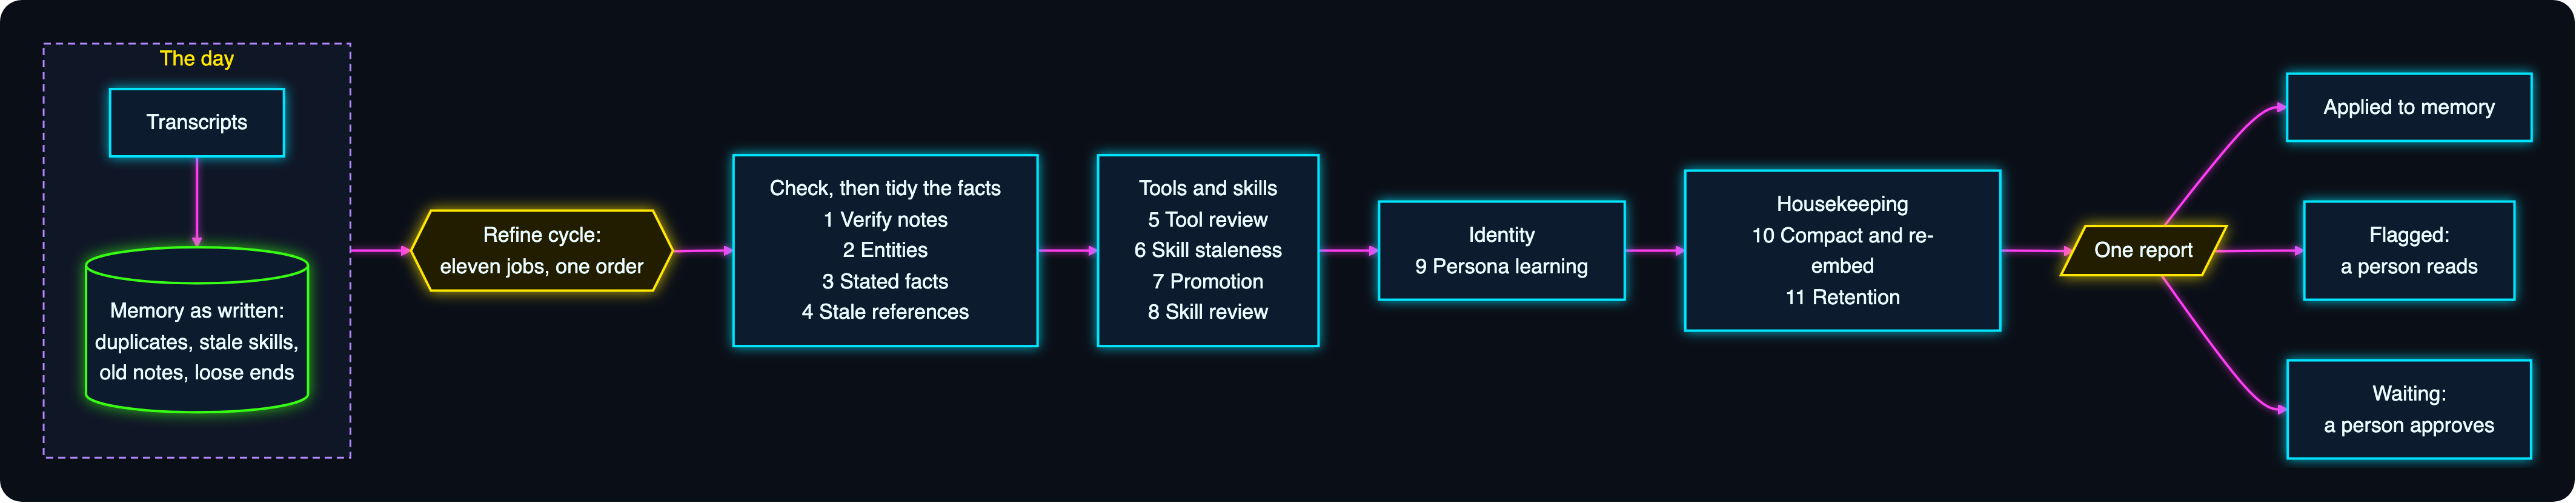

That is the *what*. The *when* is easier to see as a timeline. Read it in
three bands — day, night, morning — and notice who is talking to whom in
each:

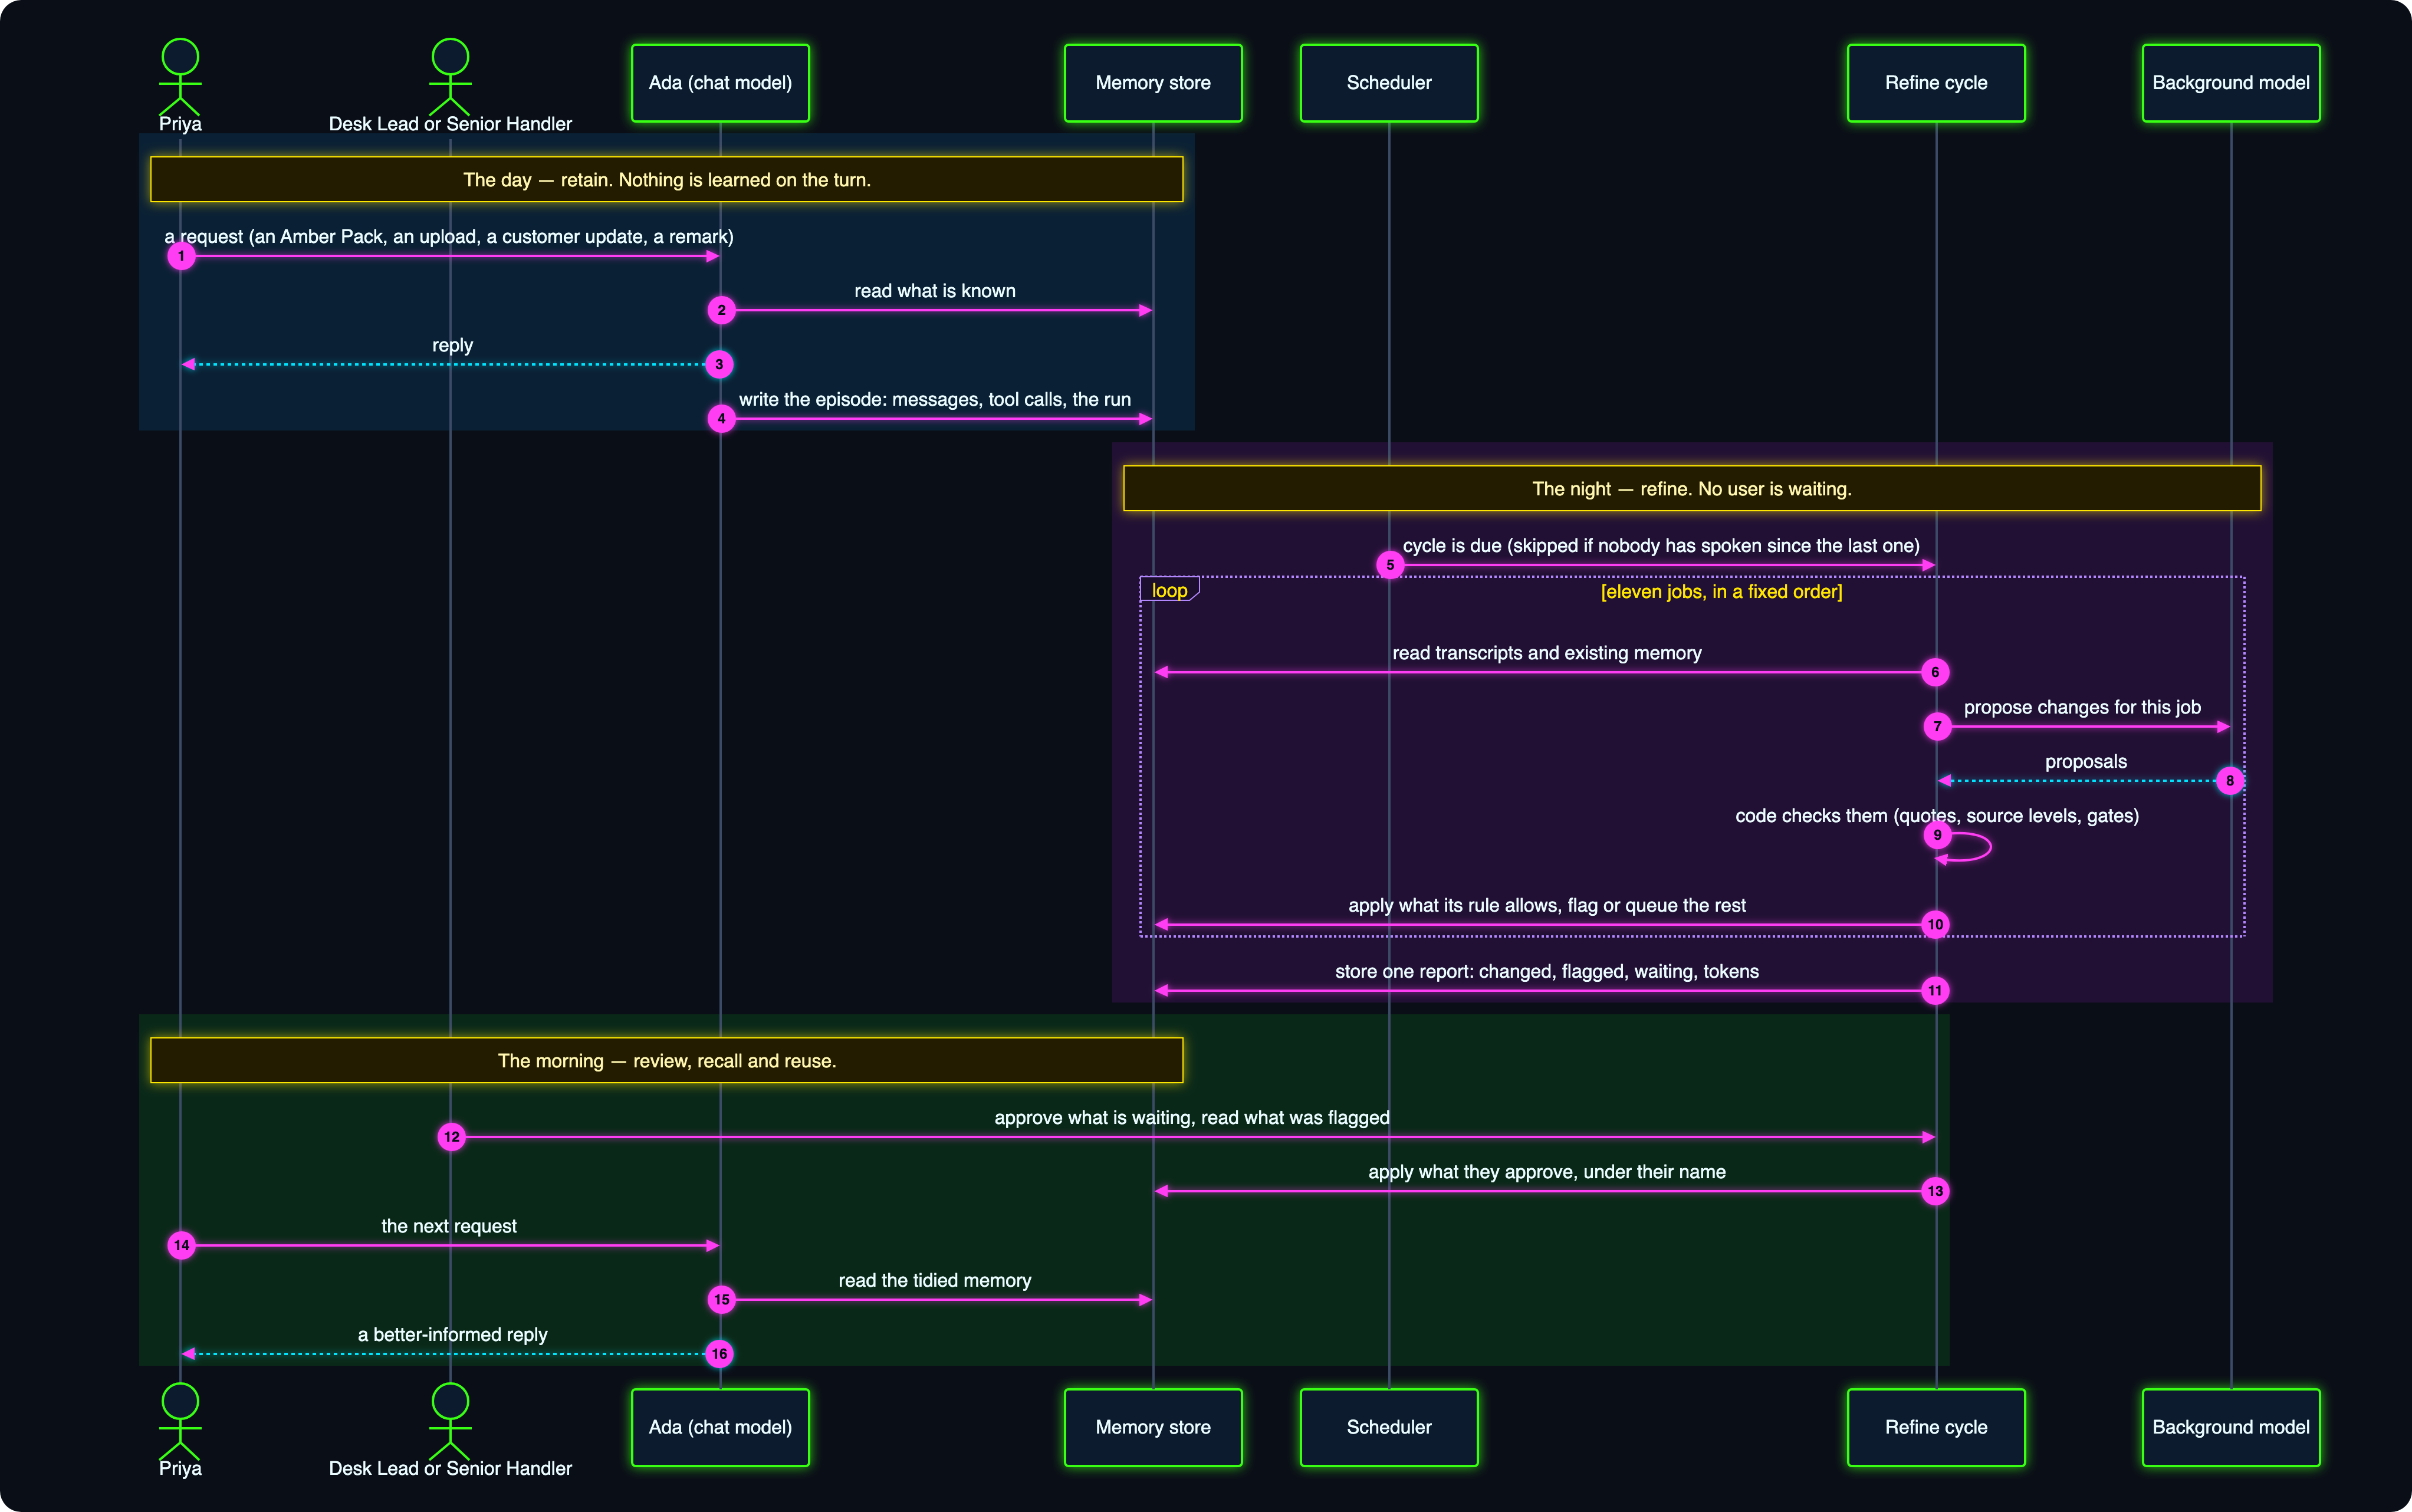

Two details in that diagram carry most of the design.

**The chat model and the background model never meet.** Priya's turns go
to one; the cycle's reasoning goes to the other. Here they happen to be the
same cheap model, but they are separate settings, and the cycle is the
first place to spend on a stronger one — nobody is waiting on it.

**The code sits between the model and the store.** The background model
*proposes*. What gets written is decided by rules the model can't argue
with: a stated fact needs the user's own words, a host value outranks a
remark, a new skill waits in shadow, guardrails are out of reach.

Capture, routing, reflection and compaction are *not* part of the cycle.
They still run after each turn, because they are about keeping the current
conversation healthy. The cycle is about what the agent should carry into
tomorrow.

# Part 2 · Setup

**What you'll learn here:** the three things every notebook in this series
needs before it can do anything — the library, a place for memory to live,
and a model — and why each is set up the way it is. **By the end** you'll
have a `provider` every agent will share, two model names, and a run id
that keeps this run apart from any other.

## 0 · Setup

Three things happen across the next three cells, and each one is deliberate.

1. **MemoRizz is imported from this repository's `src/` tree.** These notebooks
   track features that are ahead of the published package, so the cell finds
   the repository root and puts `src/` on the import path. Once the release is
   out, this becomes `pip install -U memorizz`.
2. **The store is a folder you can open.** `FileSystemProvider` is the
   zero-infrastructure backend — every memory is a JSON document on disk. All
   five notebooks write to the same folder, `calderwood_store`, next to the
   notebooks, so the whole series ends up in one place **and the MemoRizz
   local UI can connect to it** (Part 7 shows how). Delete the folder to
   start again. Oracle and MongoDB are a provider swap, not a rewrite.
3. **One small, current model.** Both the *chat model* (which answers the
   user) and the *background model* (which does the learning, off the user's
   turn) default to `gpt-6-luna`, the cheapest of OpenAI's current models.

You need an `OPENAI_API_KEY` in the environment (or in a `.env` file at the
repository root). The key is read from the environment and never written
into the notebook or the store.

**First, find the library and the key.** Nothing MemoRizz-specific yet:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `REPO` | notebook helper | Walks up from the notebook's folder to the directory that holds `src/memorizz` | Lets the notebook run against unreleased source without an install step |
| `dotenv_values`, `find_dotenv` | Python library (`python-dotenv`) | Read a `.env` file without exporting it | The key reaches the process and nothing else — it is never printed or stored |

In [1]:
import json
import logging
import os
import sys
import tempfile
import uuid
from pathlib import Path

# 1. MemoRizz: the installed package, or a source checkout named by MEMORIZZ_SRC
#    (for example MEMORIZZ_SRC=~/memorizz/src while a feature is not yet released).
SRC = os.path.expanduser(os.getenv("MEMORIZZ_SRC", ""))
if SRC and SRC not in sys.path:
    sys.path.insert(0, SRC)

# The key comes from the environment, or from the repository's .env file.
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**Next: where memory lives, which models do the work, and the world they
work in.** Every later cell leans on what this one defines.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `FileSystemProvider` | MemoRizz API | The *memory provider*: the object every agent reads and writes its memory through | One provider, shared by Ada and her twin, so both live in the same store — and the UI can open it |
| `FileSystemConfig(root_path=…, embedding_provider=…, embedding_config=…)` | MemoRizz API | Points the provider at a folder and says how text becomes vectors (a small OpenAI model at 256 dimensions) | Cheap, and plenty for a fixture this size. Swap the provider for Oracle or MongoDB and nothing else changes |
| `MemAgent`, `MemoryType` | MemoRizz API | The agent class, and the names of the memory stores (`ENTITY_MEMORY`, `SKILLBOX`, …) | Imported here, used from Part 3 on |
| `MEMORIZZ_HOME` | MemoRizz setting | Where MemoRizz keeps its own local state | Pointed at a throwaway folder so a MemoRizz setup you already have is left alone |
| `CHAT_MODEL`, `BACKGROUND_MODEL` | notebook setting | The model that answers the user, and the model that does the learning | Two jobs. The cycle runs entirely on the second |
| `cw` (`calderwood_world`) | Calderwood world | The module beside the notebooks that holds Calderwood's people, teams, codes and per-round policy values | One spelling of every fact across all five notebooks: the Amber Pack deadline here is the same number notebook 03 supersedes |
| `RUN` | notebook helper | A short random suffix added to every id | The store is shared, so the suffix keeps this run's agents apart from yesterday's |

In [2]:
# 2. One store for the whole series, in a folder the local UI can open.
STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "calderwood_store").resolve()
os.environ["MEMORIZZ_HOME"] = tempfile.mkdtemp(prefix="memorizz-nb-home-")  # leave your own MemoRizz home alone
logging.disable(logging.WARNING)  # keep the lesson's output readable

import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemAgent, MemoryType

import calderwood_world as cw  # the shared Calderwood world, beside this notebook

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)

# 3. The cheapest current model, for both jobs. Override either from the environment.
CHAT_MODEL = os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")
BACKGROUND_MODEL = os.getenv("MEMORIZZ_NB_BACKGROUND_MODEL", "gpt-6-luna")
RUN = uuid.uuid4().hex[:6]  # keeps ids unique if you re-run the notebook

**Last piece of setup: two helpers for finding this run in the UI.** Neither
teaches anything about learning, and both get used once, at the very end.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `record_run(notebook, **ids)` | notebook helper | Writes this run's agent and conversation ids to `notebook_runs.json` in the store | Five notebooks share the store; this is how you find *this* run's Ada among them |
| `ui_command()` | notebook helper | Builds the `memorizz ui` command that opens the store, with the embedding settings the store was written with | The UI has to embed queries the same way the notebook did, or search finds nothing |

In [3]:
def record_run(notebook, **ids):
    """Note which agents and conversations this run made, so they are easy to find in the UI."""
    path = STORE / "notebook_runs.json"
    runs = json.loads(path.read_text()) if path.exists() else {}
    runs[notebook] = {"run": RUN, **ids}
    path.write_text(json.dumps(runs, indent=2))


def ui_command():
    """The command that opens this store in the MemoRizz local UI."""
    return (
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path {STORE.name}"
    )


print("memorizz      :", getattr(memorizz, "__version__", "dev"), "(from src/)" if REPO else "(installed)")
print("store         :", STORE.name, "(a folder beside this notebook)")
print("chat model    :", CHAT_MODEL, "| background model:", BACKGROUND_MODEL)
print("run id        :", RUN)

memorizz      : 0.17.24 (from src/)
store         : store_cw2_05 (a folder beside this notebook)
chat model    : gpt-6-luna | background model: gpt-6-luna
run id        : e15bf4


# Part 3 · The desk: tools, two agents, and the memory they inherit

**What you'll learn here:** how the experiment is built so that exactly one
thing differs between Ada and her twin, and what "untidy memory" looks like
as actual records — a duplicate entity, a skill whose tool has gone, a skill
that misfires, notes nobody reads, a fact whose source has vanished and a
how-to note that names a retired system. **By the end** you'll have two
agents that are identical in every way that could affect an answer, each
holding the same six flaws.

## 1 · The systems Ada can touch

Ada gets five small tools into Calderwood's systems. They are deliberately
dull: this notebook is about *when* learning happens, not about clever
tools. (Notebook 04 is where the tools misbehave.)

**First, the claims on Priya's desk**, and the one check every Beacon tool
shares.

**The dataset: `CLAIMS`.** Eight claims, all Priya's, as Beacon would hold
them. They are the things the day's work is *about*; nothing is learned from
the table itself. How to read one row:

| Field | In the row `CW-512318` | What it means |
|---|---|---|
| `claim_ref` | `CW-512318` | The claim's reference in Beacon: `CW-` and six digits. A tool given anything else refuses |
| `peril` | `theft` | What happened to the customer: theft, storm, escape of water (a burst pipe or leak), subsidence (the ground moving under a house), accidental damage |
| `status` | `Q3` | Where the claim has got to. Q3: waiting for the customer's documents. Q7: waiting for a surveyor's report. Q12: paid. A referral to the fraud team will change it to Q9 |
| `reserve` | `9500` | The money Calderwood has set aside for this claim, in pounds |
| `handler` | `Priya Shah` | Who is working it |

There is no customer name on a claim here, on purpose. A customer is detail
about one case, and should never end up in a skill, a persona or a note.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `ROUND` | notebook setting | Which round of Calderwood's rules is in force: 2, January 2027 | Every policy value below is read for this round, never typed in |
| `CLAIMS` | Calderwood fixture | Eight claims, each with a `CW-` reference, a peril, a Beacon status and a reserve in pounds | The day's work happens on these; customers are deliberately absent — they are episodic detail and should never reach a skill or a persona |
| `_claim(claim_ref)` | notebook helper | Returns the claim, or refuses the way Beacon would | One place for "a claim reference is `CW-` plus six digits" |
| `cw.is_claim_ref` | Calderwood world | Tests that shape | The same rule notebook 04 turns into a learned usage note |

In [4]:
ROUND = 2  # January 2027: the month the round 2 rules land

CLAIMS = {
    ref: {"claim_ref": ref, "peril": peril, "status": status, "reserve": reserve, "handler": "Priya Shah"}
    for ref, peril, status, reserve in [
        ("CW-512044", "escape of water", "Q7", 4200), ("CW-512131", "storm", "Q3", 1800),
        ("CW-512207", "theft", "Q12", 950), ("CW-512290", "subsidence", "Q7", 22000),
        ("CW-512318", "theft", "Q3", 9500), ("CW-512402", "accidental damage", "Q3", 650),
        ("CW-512467", "escape of water", "Q7", 2900), ("CW-512533", "storm", "Q3", 5400),
    ]
}


def _claim(claim_ref):
    """The claim record, or the refusal Beacon would give."""
    if not cw.is_claim_ref(claim_ref):
        raise ValueError("claim_ref must be CW- followed by six digits")
    if claim_ref not in CLAIMS:
        raise ValueError("no such claim in Beacon")
    return CLAIMS[claim_ref]


print(len(CLAIMS), "claims on Priya's desk | rules in force: round", ROUND, f"({cw.ROUND_NAMES[ROUND]})")

8 claims on Priya's desk | rules in force: round 2 (January 2027)


**The three tools an Amber Pack referral needs.** When a handler spots
fraud indicators, the desk's procedure is three steps, in this order: look
the claim up, mark it as referred (which sets Beacon status Q9), raise the
pack. By the end of the day Ada will have done that three times — precisely
the kind of repetition the cycle is meant to notice.

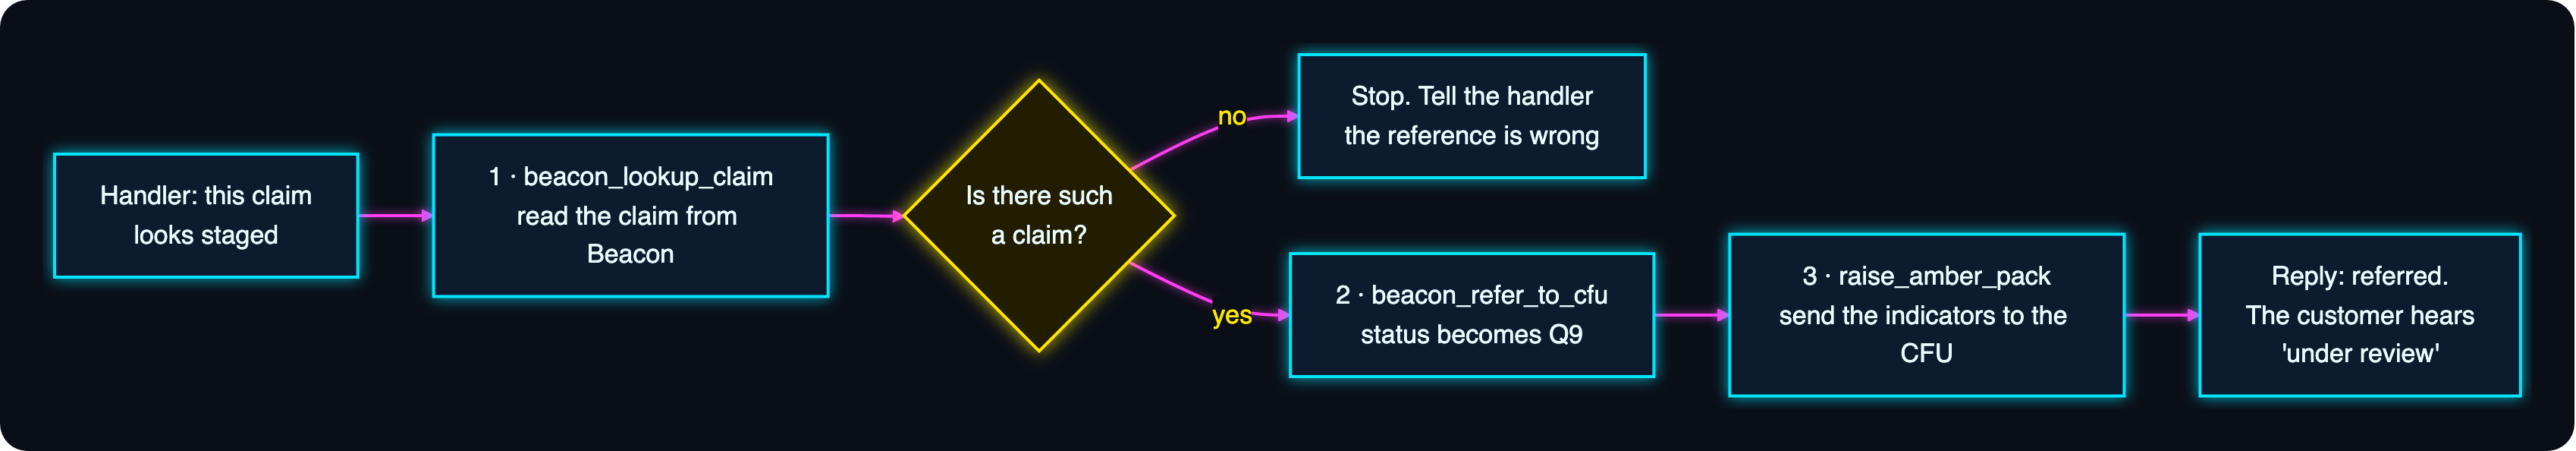

**How to read it.** Left to right is the order of the calls. The diamond is
the only question on the path, and Beacon answers it, not Ada.

| Step | Tool | When it applies | How it ends |
|---|---|---|---|
| 1 | `beacon_lookup_claim` | Always first: nothing is done to a claim nobody has read | The claim, or a refusal if the reference isn't a real `CW-` claim |
| *(branch)* | — | The reference is wrong | Ada stops and says so. No referral |
| 2 | `beacon_refer_to_cfu` | The claim exists | Its Beacon status becomes Q9 ("referred to the CFU") |
| 3 | `raise_amber_pack` | After the status is set | The pack, with the handler's reasons, goes to the Counter Fraud Unit |
| *(reply)* | — | After step 3 | Ada tells the handler it is done. Anything written *to the customer* says "under review" and nothing more |

This path — these three tools, in this order — is what the promotion job
will later recognise as one procedure, done three times.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `beacon_lookup_claim(claim_ref)` | Calderwood tool | Fetches a claim from Beacon | Step 1 of the referral. Its result goes through `cw.money`, so the reserve arrives labelled `"currency": "GBP"` and Ada has no reason to guess at dollars |
| `beacon_refer_to_cfu(claim_ref)` | Calderwood tool | Marks the claim as referred to the Counter Fraud Unit: status Q9 | Step 2. Q9 is internal only, which is why the instruction below keeps it out of customer wording |
| `raise_amber_pack(claim_ref, indicators)` | Calderwood tool | Raises the fraud referral pack, with the indicators the handler saw | Step 3. `indicators` is free text and differs every time — the part of a run a skill must *not* memorise |
| `cw.money(**fields)` | Calderwood world | Adds `"currency": "GBP"` to a tool result | Every result that mentions money says which currency |

In [5]:
def beacon_lookup_claim(claim_ref: str) -> dict:
    """Fetch a claim from Beacon by its reference, for example CW-512318."""
    return cw.money(**_claim(claim_ref))


def beacon_refer_to_cfu(claim_ref: str) -> dict:
    """Mark a claim in Beacon as referred to the Counter Fraud Unit (status Q9)."""
    _claim(claim_ref)["status"] = "Q9"
    return {"ok": True, "claim_ref": claim_ref, "status": "Q9"}


def raise_amber_pack(claim_ref: str, indicators: str) -> dict:
    """Raise an Amber Pack (the fraud referral pack) on a claim, naming the fraud indicators seen."""
    _claim(claim_ref)
    return {"ok": True, "claim_ref": claim_ref, "amber_pack": "raised", "sent_to": "Counter Fraud Unit"}

**Two more tools, and one that is conspicuously missing.** Neither of these
is used during the day. They are here because two skills in Ada's memory
depend on them — and because one of those skills also depends on a tool
that no longer exists.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `set_hsr(claim_ref)` | Calderwood tool | Puts a claim on HSR: Hold for Surveyor Review | Used by the *Put a claim on hold* skill we'll meet in section 3 |
| `beacon_upload_attachment(claim_ref, file_mb)` | Calderwood tool | Attaches a file; refuses anything over 25MB with BCN-217 | Step 1 of the *Large attachment* skill |
| `cw.CalderwoodError(code)` | Calderwood world | A system refusal that carries its code and meaning | The error text is Calderwood's, not ours |
| `cw.policy(name, round=…)` | Calderwood world | The value of a policy in a given round | The 25MB limit is read, not typed |
| `TOOLS` | notebook fixture | The five tools both agents get | **`drop_send_link` is not in it.** It was removed in January, when Drop was retired. Hold that thought |

In [6]:
def set_hsr(claim_ref: str) -> dict:
    """Put a claim on HSR (Hold for Surveyor Review)."""
    _claim(claim_ref)["hsr"] = True
    return {"ok": True, "claim_ref": claim_ref, "hsr": True}


def beacon_upload_attachment(claim_ref: str, file_mb: float) -> dict:
    """Attach a file to a claim in Beacon."""
    _claim(claim_ref)
    if file_mb > cw.policy("attachment_limit_mb", round=ROUND):
        raise cw.CalderwoodError("BCN-217")
    return {"ok": True, "claim_ref": claim_ref, "attached_mb": file_mb}


TOOLS = [beacon_lookup_claim, beacon_refer_to_cfu, raise_amber_pack, set_hsr, beacon_upload_attachment]
print("tools in January  :", ", ".join(tool.__name__ for tool in TOOLS))
print("removed with Drop :", "drop_send_link")

tools in January  : beacon_lookup_claim, beacon_refer_to_cfu, raise_amber_pack, set_hsr, beacon_upload_attachment
removed with Drop : drop_send_link


## 2 · Two agents: Ada, and the twin nobody tidies up after

To know whether the cycle is worth having, we need something to compare it
with. So we build the agent twice from one function. Same model, same
tools, same instruction, same persona, same guardrails — and, in section 3,
the same inherited memory. **One thing differs: Ada's upkeep runs as a
refine cycle. The twin's never runs at all.**

That makes the twin a fair opponent, not a strawman. She isn't an amnesiac
and she isn't a blank slate. She keeps every message and every tool run,
she can look up the same entity records, and she carries the same skills.
What she never gets is the pass that reads it all back.

**Who they are, before how they learn.** The identity both share:

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `USER_ID`, `AGENT_ID`, `MEMORY_ID` (and the twin's) | notebook setting | Who is speaking, which agent, and whose memory | Every read and write in MemoRizz is scoped by these three. Priya's id comes from `cw.USER_IDS` |
| `Persona(name=…, role=…, guardrails=[…])` | MemoRizz API | The agent's identity: who it is, what it's for, and the rules it never breaks | Persona learning (notebook 02) can add to `goals`. Nothing that learns can write `guardrails` |
| `GUARDRAILS` | notebook fixture | Two rules for Calderwood's assistant | We'll check they are untouched after the cycle |
| `cw.HOUSE_INSTRUCTION` | Calderwood world | The sentence every Calderwood assistant carries: who Ada is, and that money is in pounds sterling | Shared by all five notebooks |
| `INSTRUCTION` | notebook fixture | The house sentence, plus how to raise an Amber Pack and how to word a customer update | Both agents are *told* the procedure. The cycle's job isn't to discover it — it's to notice it is being used |

In [7]:
from memorizz.long_term.semantic.persona.persona import Persona

USER_ID = f"{cw.USER_IDS['Priya Shah']}-{RUN}"
AGENT_ID, MEMORY_ID = f"ada-{RUN}", f"calderwood-{RUN}"
TWIN_ID, TWIN_MEMORY_ID = f"ada-twin-{RUN}", f"calderwood-twin-{RUN}"

GUARDRAILS = [
    "Never give a customer a coverage decision.",
    "Never tell a customer the reason a payment was frozen.",
]
INSTRUCTION = (
    cw.HOUSE_INSTRUCTION + " Be brief. Call a tool only when the handler asks you to do "
    "something in a system; to draft wording, use what the handler told you. "
    "To raise an Amber Pack: look the claim up in Beacon, mark it referred to the CFU, "
    "then raise the pack. A customer update is plain English and never mentions Q9, "
    "the CFU or fraud: say the claim is under review."
)


def desk_persona():
    persona = Persona(name="Ada", role="Calderwood's internal claims support assistant", guardrails=GUARDRAILS)
    persona.goals = "Help claims handlers resolve claims quickly and correctly."
    persona.background = "Works with the claims desk at Calderwood Insurance, a UK insurer."
    return persona

**Now the one difference, written down as two dictionaries.** Read
`CYCLE_ON` as a set of **apply rules** — who is allowed to change what
without asking. Each line is one of the mechanisms from the earlier
notebooks.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `continual_learning_config` | MemoRizz API | Settings for the workflow-to-skill loop (notebook 01) | Both agents have a skill store; only Ada's is ever maintained |
| `min_executions`, `min_distinct_queries` | MemoRizz API | Gates: how many successful runs, in how many different wordings, before a procedure may become a skill | Set to 3 and 3, so three Amber Packs in three wordings is exactly enough |
| `retrieval_min_similarity` | MemoRizz API | How close a request must be to a skill for the skill to be loaded | 0.5 here (the default is 0.70) because our requests are one short sentence |
| `require_shadow` | MemoRizz API | A new skill lands in **shadow**: stored, not used, until a person activates it | Nothing gets a promotion in its sleep |
| `promotion_every_n_runs` | MemoRizz API | The per-run counter that triggers promotion; `0` means never | The twin's setting. Her skills are read, never reviewed |
| `memory_consolidation={"auto_apply": True, "max_threads": 12}` | MemoRizz API | Entity tidying and stated facts (notebook 03). `max_threads` is how many recent conversations one pass reads (default 5) | Reversible, so it applies itself. The day has ten conversations, so we raise the limit to read all of them |
| `"refine_verify": True` | MemoRizz API | Lets the cycle check stored facts against the conversations they cite | On by default. It can only raise a flag |
| `"refine_tool_review": "propose"` | MemoRizz API | Lets the cycle review how tools were called (notebook 04) and *propose* revisions. `"auto"` would apply them; `"off"` skips the job | The default. A change to a tool's description waits for a person |
| `"refine_compact": True` | MemoRizz API | Lets the cycle re-embed records whose text changed, so search follows the edit | On by default. It writes vectors, never text |
| `persona_learning={"auto_apply": False, "min_conversations": 3}` | MemoRizz API | Identity (notebook 02): propose one sentence, seen in at least three conversations | A change to *who Ada is* waits for a person |
| **`refine_cycle=True`** | MemoRizz API | Turns the per-turn counters off. Upkeep runs when the cycle runs | The switch this notebook is about |

In [8]:
SKILL_RULES = {"min_executions": 3, "min_distinct_queries": 3, "retrieval_min_similarity": 0.5}

# Ada: every kind of upkeep is on, and all of it waits for the cycle.
CYCLE_ON = dict(
    continual_learning_config={**SKILL_RULES, "require_shadow": True},
    memory_consolidation={
        "enabled": True, "auto_apply": True, "max_threads": 12,
        # The cycle's newer jobs. These are the defaults, written out so you can see them.
        "refine_verify": True, "refine_tool_review": "propose", "refine_compact": True,
    },
    persona_learning={"enabled": True, "auto_apply": False, "min_conversations": 3},
    refine_cycle=True,
)

# The twin: the same skill store, and nothing that ever maintains it.
CYCLE_OFF = dict(
    continual_learning_config={**SKILL_RULES, "promotion_every_n_runs": 0},
)

**The factory.** One function builds both; `upkeep` is the only argument
that differs.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `make_agent(agent_id, memory_id, name, upkeep)` | notebook helper | Builds and saves one agent | Guarantees the two differ only in `upkeep` |
| `MemAgent(llm_config=…, background_llm_config=…)` | MemoRizz API | The chat model, and the separate model the learning runs on | The cycle never touches the chat model |
| `Toolbox(memory_provider=…, agent_id=…)` | MemoRizz API | A catalogue of tools kept in memory: one stored entry per tool, with its description | The cycle's tool review revises *catalogue entries*, so an agent given a bare list of functions has nothing to review. Each agent gets its own |
| `toolbox.register_tool(function)` | MemoRizz API | Adds one function to the catalogue; the description starts as its docstring | Same five tools for both agents |
| `MemAgent(persona=…, instruction=…, tools=toolbox)` | MemoRizz API | Identity, standing instruction, and the tools the agent may use | Identical for both |
| `MemAgent(memory_provider=…, memory_ids=[…], agent_id=…)` | MemoRizz API | Where memory lives and which memory is this agent's | Same store, separate memories |
| `continual_learning=True` | MemoRizz API | Gives the agent a skill store and records each tool-using run as a *workflow* | Both need it: skills are part of the memory they inherit |
| `with_entity_memory(True, capture=False)` | MemoRizz API | Entity memory on, background capture after each message **off** | Nothing is learned on the turn, for either agent |
| `tool_manager.remove_tool("entity_memory_upsert")` | MemoRizz API | Takes away the tool that lets the chat model write an entity mid-turn | Both can *look entities up*; neither can write one |
| `save()` | MemoRizz API | Stores the agent | The cycle's report is kept against the saved agent, and a saved agent is one the UI can open |

Switching off capture and the upsert tool isn't how you'd run production.
It is how you run an experiment: the day becomes pure *retain*, so every
change you see afterwards was made by the cycle.

In [9]:
from memorizz import Toolbox


def make_agent(agent_id, memory_id, name, upkeep):
    """The same agent twice. `upkeep` is the only thing that differs."""
    toolbox = Toolbox(memory_provider=provider, agent_id=agent_id)
    for tool in TOOLS:
        toolbox.register_tool(tool)
    built = MemAgent(
        llm_config={"provider": "openai", "model": CHAT_MODEL},
        background_llm_config={"provider": "openai", "model": BACKGROUND_MODEL},
        persona=desk_persona(),
        instruction=INSTRUCTION,
        tools=toolbox,
        memory_provider=provider,
        memory_ids=[memory_id],
        agent_id=agent_id,
        name=name,
        streaming=False,
        continual_learning=True,
        **upkeep,
    )
    built.with_entity_memory(True, capture=False)  # no capture after each message
    built.tool_manager.remove_tool("entity_memory_upsert")  # and no mid-turn write by the model
    built.save()
    return built

**Build both and compare the switches.** The table this prints is the whole
experimental design: every row that differs is a row about *upkeep*.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent`, `twin` | notebook fixture | Ada with `CYCLE_ON`, her twin with `CYCLE_OFF` | The two names every later cell uses |
| `who.refine_cycle` | MemoRizz API | Whether this agent's upkeep runs as a cycle | True for Ada only |
| `who.refine_interval_hours` | MemoRizz API | How often a scheduled cycle is due (default 24) | Used in section 11, when the cycle goes on a clock |
| `switches(who)` | notebook helper | Seven rows describing one agent's upkeep | Printed side by side |

In [10]:
agent = make_agent(AGENT_ID, MEMORY_ID, f"Ada · refine cycle ({RUN})", CYCLE_ON)
twin = make_agent(TWIN_ID, TWIN_MEMORY_ID, f"Ada's twin · no cycle ({RUN})", CYCLE_OFF)


def switches(who):
    cycle = who.refine_cycle
    return [
        ("refine_cycle", cycle),
        ("skill store", bool(who.continual_learning)),
        ("consolidation", "in the cycle" if cycle else "off"),
        ("persona learning", "in the cycle" if cycle else "off"),
        ("promotion", "in the cycle" if cycle else "never (counter at 0)"),
        ("tool review", "in the cycle, proposes" if cycle else "never"),
        ("verify, re-embed", "in the cycle" if cycle else "never"),
    ]


print(f"{'':<20}{'Ada':<18}twin")
for (label, ada_value), (_, twin_value) in zip(switches(agent), switches(twin)):
    print(f"{label:<20}{str(ada_value):<18}{twin_value}")
print(f"{'cycle every':<20}{agent.refine_interval_hours:.0f} hours")

                    Ada               twin
refine_cycle        True              False
skill store         True              True
consolidation       in the cycle      off
persona learning    in the cycle      off
promotion           in the cycle      never (counter at 0)
tool review         in the cycle, proposesnever
verify, re-embed    in the cycle      never
cycle every         24 hours


`refine_cycle=True` only changes **when** the jobs run. With it on, the
counters for consolidation, promotion and persona learning are off, so
nothing runs twice. With it off (the default), nothing about your agent
changes. It is a scheduling decision, not a new capability — which is what
makes it safe to turn on.

## 3 · The memory both inherit

Now the untidy part. Everything in this section is a **seeded fixture**: we
are writing, in a few cells, the state that months of real use would have
left behind. Where MemoRizz has a public API for the write, we use it
(`upsert_entity`, `add_skill`, `ingest_knowledge`); the only liberties are
the backdated timestamps and the usage counts on the two skills, which a
notebook can't earn in an afternoon. Both agents get exactly the same
fixtures.

**The dataset, in one table.** Four kinds of record, each seeded for a
reason: it gives one of the cycle's jobs something real to find.

| Group | How many | What a correct cycle does with it | The job it feeds |
|---|---|---|---|
| **3a** Entity records for the fraud team | 2, for one team | Merges them, keeps the handbook's values | Entities |
| **3a** Entity records about uploads (`Drop`, `BCN-217`) | 2 | Updates `Drop` when Priya says it has been retired | Stated facts |
| **3b** Skills | 2 | Deprecates the one whose tool is gone; flags the one that misfires | Skill staleness, Skill review |
| **3c** Old desk notes | 20 | Plans to retire the ones nobody has read | Retention |
| **3d** A fact from a deleted conversation | 1 | Flags it: its source can no longer be read | Verify notes |
| **3d** A how-to note that names Drop | 1 | Flags it once `Drop` is retired; rewrites nothing | Stale references |

An **entity record** is MemoRizz's unit of fact: a named thing (a team, a
system, a person) with a list of *attributes*. How to read one, using the
`CFU` record about to be written:

| Field | In the `CFU` record | What it means |
|---|---|---|
| `name` | `CFU` | What the thing is called. The Counter Fraud Unit has two records because it has two names |
| `entity_type` | `team` | What kind of thing it is |
| attribute `name` / `value` | `office` = `Leeds` | One fact about it |
| attribute `source` | `turn` | Where the fact came from: `turn` means somebody said it in a conversation; `policy_handbook` means the host application wrote it |
| source level | `2` | How far to trust the writer: **3** the host application, **2** a user, **1** something the cycle inferred. Higher wins a disagreement |

### 3a · The fraud team, twice

Two records exist for one team, and they are the classic mess:

- **`CFU`** is the team under its short name, left by a conversation in
  September at **source level 2** (stated by a user). It says Leeds, and an
  Amber Pack deadline of 2 working days. Both were true at the time.
- **`Counter Fraud Unit`** is the same team, written this month by the host
  application from the January policy handbook. A direct SDK write is
  **level 3** — the most trusted. It says Manchester, and 3 working days.

(Notebook 03 is the long version of why source levels exist. The short
version: what your policy handbook says should not be overwritten by what
somebody thinks they heard.)

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `EntityMemory(provider)` | MemoRizz API | The store of facts about people, teams, systems and policies | What Ada looks things up in |
| `upsert_entity(name=…, entity_type=…, attributes=[…], memory_id=…, user_id=…)` | MemoRizz API | Writes an entity, or adds attributes to one that exists | The host's way in. Each attribute is a `name`, a `value` and a `source` |
| `source_level=2` | MemoRizz API | Says how much to trust the writer: 3 host (the default for an SDK write), 2 user, 1 consolidation | Decides who wins when two records disagree |
| `entity_aliases`, `source_level` | MemoRizz API | Read a record's other names, and an attribute's level | Imported now, used when we print memory |
| `deadline(round)` | notebook helper | The Amber Pack deadline in a round, read from `cw.policy` | Round 1 gives 2 working days, round 2 gives 3 — the disagreement is Calderwood's own history |
| `seed_fraud_team(scope)` | notebook helper | Writes the two records | The duplicate the cycle's first job is there to find |

In [11]:
from memorizz.long_term.semantic.entity_memory.entity_memory import EntityMemory, entity_aliases, source_level

entities = EntityMemory(provider)
FRAUD_TEAM = cw.TEAMS["Counter Fraud Unit"]


def deadline(round):
    return f"{cw.policy('amber_pack_days', round=round)} working days"


def seed_fraud_team(scope):
    """One team, twice: as a September conversation left it, and as the January handbook has it."""
    said = [("led_by", FRAUD_TEAM["lead"]), ("office", "Leeds"), ("amber_pack_deadline", deadline(1))]
    entities.upsert_entity(
        name="CFU", entity_type="team", source_level=2, **scope,
        attributes=[{"name": name, "value": value, "source": "turn"} for name, value in said],
    )
    handbook = [("led_by", FRAUD_TEAM["lead"]), ("office", "Manchester"), ("amber_pack_deadline", deadline(ROUND))]
    entities.upsert_entity(
        name="Counter Fraud Unit", entity_type="team", **scope,
        attributes=[{"name": name, "value": value, "source": "policy_handbook"} for name, value in handbook],
    )

**Two more records, about uploads.** These aren't duplicates; they are
simply *out of date in one place*. Memory still believes Drop is in use,
because the last person to mention it said so, in the autumn.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `seed_systems(scope)` | notebook helper | Writes `Drop` (level 2, "in use") and `BCN-217` (level 3, from the handbook) | Priya will contradict the first one this afternoon. Watch what the cycle does with her remark |
| `entities.list_entities(memory_id=…, user_id=…)` | MemoRizz API | Every live entity in one memory, for one user | How we read memory back, here and in every snapshot below |

Notice what the `BCN-217` record says to do: send the file *through the
customer upload portal*. It doesn't name the portal. That turns out to be a
good decision, for a reason we'll come back to in the limits section.

In [12]:
def seed_systems(scope):
    """What memory holds about the upload portal, and the error that sends people to it."""
    entities.upsert_entity(name="Drop", entity_type="system", source_level=2, **scope, attributes=[
        {"name": "used_for", "value": "customer upload portal for large files", "source": "turn"},
        {"name": "status", "value": "in use", "source": "turn"},
    ])
    entities.upsert_entity(name="BCN-217", entity_type="error code", **scope, attributes=[
        {"name": "meaning", "value": cw.ERRORS["BCN-217"], "source": "policy_handbook"},
        {"name": "fix", "value": "split the file, or ask the customer to send it through the customer upload portal",
         "source": "policy_handbook"},
    ])


for memory_id in (MEMORY_ID, TWIN_MEMORY_ID):
    scope = {"memory_id": memory_id, "user_id": USER_ID}
    seed_fraud_team(scope)
    seed_systems(scope)
    print(memory_id, "->", [record["name"] for record in entities.list_entities(**scope)])

calderwood-e15bf4 -> ['CFU', 'Counter Fraud Unit', 'Drop', 'BCN-217']
calderwood-twin-e15bf4 -> ['CFU', 'Counter Fraud Unit', 'Drop', 'BCN-217']


### 3b · Two skills from the autumn

A **skill** is a short document — a `SKILL.md` — that MemoRizz distils from
a procedure that kept succeeding, and then loads into the prompt whenever a
matching request arrives. Notebook 01 follows one from its first run to its
demotion. Here we need two that are already middle-aged.

First, a helper that writes a `SKILL.md` in the shape the distiller
produces, so our fixtures look like the real thing.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `skill_md(name, description, precondition, tools, steps)` | notebook helper | Renders a `SKILL.md`: YAML frontmatter (name, description, preconditions, tools), then *When to apply* and a numbered *Procedure* | The same four frontmatter keys validation requires of a distilled skill |

In [13]:
def skill_md(name, description, precondition, tools, steps):
    """A SKILL.md in the shape the distiller writes: frontmatter, when to apply, procedure."""
    numbered = "\n".join(f"{number}. {step}" for number, step in enumerate(steps, 1))
    return (
        f"---\nname: {name}\ndescription: {description}\n"
        f"preconditions:\n  - {precondition}\ntools: [{', '.join(tools)}]\n---\n\n"
        f"# {name}\n\n## When to apply\n{description}\n\n## Procedure\n{numbered}\n"
    )

**Then a helper that puts a skill into an agent's skill store as if it had
been promoted in the autumn.**

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Skill(name=…, description=…, content=…, preconditions=…, tools_used=…, queries=…)` | MemoRizz API | One skill record. `description`, `preconditions` and `queries` are what retrieval matches a request against; `content` is the `SKILL.md`; `tools_used` is what it depends on | `tools_used` is what the staleness job checks. `description` is what the review job judges |
| `SkillStatus.ACTIVE` | MemoRizz API | The status of a skill that is loaded for matching requests. The others: `candidate`, `shadow`, `deprecated`, `demoted` | Both fixtures start active: live, trusted, and — as we'll see — wrong in two different ways |
| `stats={…}` | MemoRizz API | The skill's running counts: `activations` (times loaded), `successes`, `deviations` (loaded, and the agent went another way) | MemoRizz keeps these itself as a skill is used. Here we set them, because a notebook can't live through an autumn |
| `agent.continual_learning_manager.skillbox.add_skill(skill)` | MemoRizz API | Stores the skill for that agent | The public way to hand an agent a skill you wrote yourself |
| `inherit_skill(agent, …)` | notebook helper | Builds the `Skill` and adds it, backdated 70 days | Same call for Ada and for the twin |

In [14]:
from datetime import datetime, timedelta, timezone

from memorizz.long_term.procedural.skillbox.skill import Skill, SkillStatus

AUTUMN = datetime.now(timezone.utc) - timedelta(days=70)


def inherit_skill(agent, name, description, precondition, tools, steps, queries, stats):
    """Put an ACTIVE skill in an agent's skill store, as a promotion in the autumn would have left it."""
    skill = Skill(
        name=name, description=description, preconditions=[precondition],
        content=skill_md(name, description, precondition, tools, steps),
        tools_used=tools, queries=queries, stats=stats,
        agent_id=agent.agent_id, user_id=USER_ID,
        status=SkillStatus.ACTIVE, created_at=AUTUMN, promoted_at=AUTUMN,
    )
    agent.continual_learning_manager.skillbox.add_skill(skill)

**The two skills themselves.** Read them the way a reviewer would.

- **Large attachment** was a good skill. Nine activations, nine successes.
  Its procedure: try the upload, and if Beacon answers BCN-217, call
  `drop_send_link` to send the customer a Drop link. Then January happened.
  The skill didn't change. The world did.
- **Put a claim on hold** was never a good skill. Its description — *"use
  when a handler wants a claim paused or held"* — is far too generous. It
  gets loaded when someone says "hold the payment" or "hold off on that
  letter", Ada reads it, and goes another way. Eight activations, six
  deviations.

Neither problem is visible from inside a conversation. Both are exactly
what two of the cycle's jobs — *Skill staleness* and *Skill review* — exist
to catch.

How to read one skill, using *Large attachment* from the cell below:

| Field | In *Large attachment* | What it means |
|---|---|---|
| name | `Large attachment` | What a person calls it |
| description | "Use when a customer's file is too large to attach…" | When to load it. Retrieval matches a request against this |
| precondition | "The handler has a claim reference and a file to attach." | What must be true before it applies |
| tools | `beacon_upload_attachment`, `drop_send_link` | What the procedure calls. The staleness job checks every one still exists |
| steps | three numbered lines | The procedure itself, as it goes into the prompt |
| example requests | "The customer's video won't attach, BCN-217", … | Wordings that should find it |
| stats | 9 activations, 9 successes | How often it was loaded and how it went. *Put a claim on hold* shows 8 activations and 6 *deviations*: loaded, and then ignored |

In [15]:
for who in (agent, twin):
    inherit_skill(
        who, "Large attachment",
        "Use when a customer's file is too large to attach to a claim in Beacon (error BCN-217).",
        "The handler has a claim reference and a file to attach.",
        ["beacon_upload_attachment", "drop_send_link"],
        ["Call `beacon_upload_attachment` with the claim reference and the file size.",
         "If Beacon answers BCN-217, call `drop_send_link` to send the customer a Drop upload link.",
         "Tell the handler the link has gone."],
        ["The customer's video won't attach, BCN-217", "Their photos are too big for Beacon", "File over 25MB on a claim"],
        {"activations": 9, "successes": 9, "recent_outcomes": [True] * 9},
    )
    inherit_skill(
        who, "Put a claim on hold",
        "Use when a handler wants a claim paused or held.",
        "The handler names a claim.",
        ["beacon_lookup_claim", "set_hsr"],
        ["Call `beacon_lookup_claim` with the claim reference.", "Call `set_hsr` with the claim reference."],
        ["Put it on HSR", "Hold this one for the surveyor"],
        {"activations": 8, "successes": 2, "deviations": 6, "recent_outcomes": [True, True]},
    )
print("each agent inherits:", [skill.name for skill in agent.continual_learning_manager.skillbox.list_skills()])

each agent inherits: ['Large attachment', 'Put a claim on hold']


### 3c · Twenty notes nobody reads

The last flaw is the least dramatic and the most common. Over the autumn,
twenty short desk notes ended up in the knowledge base: *"customer rang to
chase"*, *"left a voicemail about the missing photos"*. Each was worth
writing down on the day. None is worth much now. All of them are still
searched on every turn.

Here they are, as plain data: twenty lines, each a claim reference, a
colon, and what somebody jotted down. (`CW-431512: customer rang to chase,
told them the surveyor is booked` is typical.) Note what they *don't*
contain: no customer names. A claim reference is enough to make a note
findable.

What a correct cycle does with them: nothing, by itself. It *plans* to
retire the ones that are old, unimportant and unread, and waits for a
person to say yes.

In [16]:
OLD_NOTES = [f"{ref}: {what}" for ref, what in [
    ("CW-431512", "customer rang to chase, told them the surveyor is booked"),
    ("CW-431640", "left a voicemail about the missing photos"),
    ("CW-431702", "customer prefers calls after 4pm"),
    ("CW-431733", "payment query, confirmed the amount by phone"),
    ("CW-431790", "second chase for the plumber's invoice"),
    ("CW-431811", "customer away until the 14th"),
    ("CW-431856", "emailed the claim form again"),
    ("CW-431902", "surveyor running late, rebooked for Thursday"),
    ("CW-431947", "customer asked for letters in large print"),
    ("CW-431988", "left a message with a neighbour"),
    ("CW-432015", "photos arrived but two are blurred"),
    ("CW-432060", "customer confirmed the new address"),
    ("CW-432104", "contractor quote expected Friday"),
    ("CW-432151", "chased the engineer's report"),
    ("CW-432199", "customer will send receipts by post"),
    ("CW-432240", "call dropped, rang back, no answer"),
    ("CW-432286", "explained the excess again"),
    ("CW-432333", "customer happy to wait for the report"),
    ("CW-432377", "sent the repair network's number"),
    ("CW-432420", "file note copied over from the old thread"),
]]
print(len(OLD_NOTES), "desk notes, for example:", OLD_NOTES[0])

20 desk notes, for example: CW-431512: customer rang to chase, told them the surveyor is booked


**Writing them, backdated.** Retention planning leaves a record alone for
its first 30 days (the *grace period*), so a note written today would never
be a candidate. Ours are dated 45 to 64 days back.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `KnowledgeBase(provider)` | MemoRizz API | The store of notes and documents an agent can search | Where the desk notes live |
| `ingest_knowledge(text, namespace=…, chunking_strategy="none", user_id=…)` | MemoRizz API | Stores text as a knowledge-base entry; `"none"` keeps each note as one record | One note, one record |
| `embeddings="off"` | MemoRizz API | Stores the note without a vector; keyword search still finds it | Twenty fewer embedding calls — and a note with no vector can only come back when its *words* match |
| `metadata={"agent_id", "memory_id", "importance", "timestamp"}` | MemoRizz API | Extra fields kept on the record | `importance` 0.1 and an old `timestamp` are two of the three things the retention score reads. The third is how often it has been recalled |
| `seed_old_notes(agent_id, memory_id)` | notebook helper | Writes the twenty notes for one agent | Same notes for both |

In [17]:
from memorizz.long_term.semantic.knowledge_base import KnowledgeBase


def seed_old_notes(agent_id, memory_id):
    """Twenty desk notes, dated 45 to 64 days back, low importance, never recalled."""
    notes = KnowledgeBase(provider)
    for index, text in enumerate(OLD_NOTES):
        written = datetime.now(timezone.utc) - timedelta(days=45 + index)
        notes.ingest_knowledge(
            text, namespace="desk-notes", chunking_strategy="none", user_id=USER_ID, embeddings="off",
            metadata={"agent_id": agent_id, "memory_id": memory_id, "importance": 0.1,
                      "timestamp": written.isoformat()},
        )


seed_old_notes(AGENT_ID, MEMORY_ID)
seed_old_notes(TWIN_ID, TWIN_MEMORY_ID)
print("seeded", len(OLD_NOTES), "old notes for each agent")

seeded 20 old notes for each agent


### 3d · Two loose ends: a fact nobody can check, and a note about to be wrong

Two last fixtures, one record each. They are the quietest of the six flaws,
and the reason four of the cycle's jobs exist.

**A fact whose source has gone.** In October, during a handover
conversation, someone told Ada that Marcus Webb (another handler) works on
the motor claims desk. Ada's turn capture stored it, as it should, and
noted *which conversation* it came from. In November that conversation was
deleted. The fact is still in memory, still read as a fact — and the only
evidence for it is a conversation that no longer exists.

| Field | In this record | What it means |
|---|---|---|
| entity | `Marcus Webb`, a `person` | Who the fact is about |
| attribute | `desk` = `motor claims` | The fact |
| `source` | `turn`, level 2 | A user said it in conversation |
| `thread_id` | `handover-october-…` | The conversation it was captured from. **No such conversation is in the store**, which is the whole point |

What a correct cycle does: flags it as `source_missing`, and leaves it
alone. It can't know whether Marcus is still on motor. A person can.

**A how-to note that names Drop.** Somebody wrote the desk a tip in the
autumn: *when a file won't attach (BCN-217, over 25MB), Drop is in use as
the customer upload portal.* Unlike the twenty notes above it is recent enough and
important enough to stay. It is also about to be contradicted, the moment
Priya says Drop has been retired.

What a correct cycle does: once the `Drop` record changes, flags the note
as a **stale reference** — text that still states a value memory has
replaced. It does not rewrite the note. Changing somebody's words is a
person's job.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `GONE_THREAD` | notebook fixture | The id of the deleted October conversation | Nothing is ever stored under it |
| attribute `"thread_id"` | MemoRizz API | Records which conversation an entity fact came from | What the verify job follows back to the transcript |
| `HOW_TO_NOTE` | notebook fixture | The tip that names Drop | One sentence, stored as one knowledge-base note with `importance` 0.8 |
| `seed_loose_ends(agent_id, memory_id)` | notebook helper | Writes both, for one agent | Same two records for Ada and the twin |

In [18]:
HOW_TO_NOTE = (
    "Desk how-to: when a file won't attach (BCN-217, over 25MB), Drop is in use as the customer upload portal. "
    "Send the customer a Drop link."
)
GONE_THREAD = f"handover-october-{RUN}"  # a conversation that was deleted in November


def seed_loose_ends(agent_id, memory_id):
    """A fact whose source conversation is gone, and a how-to note that names Drop."""
    scope = {"memory_id": memory_id, "user_id": USER_ID}
    entities.upsert_entity(name="Marcus Webb", entity_type="person", source_level=2, **scope, attributes=[
        {"name": "desk", "value": "motor claims", "source": "turn", "thread_id": GONE_THREAD},
    ])
    KnowledgeBase(provider).ingest_knowledge(
        HOW_TO_NOTE, namespace="desk-how-to", chunking_strategy="none", user_id=USER_ID, embeddings="off",
        metadata={"agent_id": agent_id, "memory_id": memory_id, "importance": 0.8},
    )


seed_loose_ends(AGENT_ID, MEMORY_ID)
seed_loose_ends(TWIN_ID, TWIN_MEMORY_ID)
print("each agent also inherits: 1 fact from a deleted conversation, 1 how-to note that names Drop")

each agent also inherits: 1 fact from a deleted conversation, 1 how-to note that names Drop


That is the morning. Two agents, identical down to the last stale note.
Nothing so far has cost a single model token (a handful of embedding calls
for the entity records and skills aside).

# Part 4 · The day, and what it leaves behind

**What you'll learn here:** what a working day actually writes to memory
when nothing is learned on the turn — and how to take a snapshot of
"everything an agent knows" that you can compare later. **By the end**
you'll have fourteen turns of real work in the store for each agent, and a
fingerprint of memory at five o'clock.

## 4 · The day's work

Before the data, the map. Part 3 seeded six things; the day is about to
leave four more. Each exists to give one of the cycle's eleven jobs
something real to do:

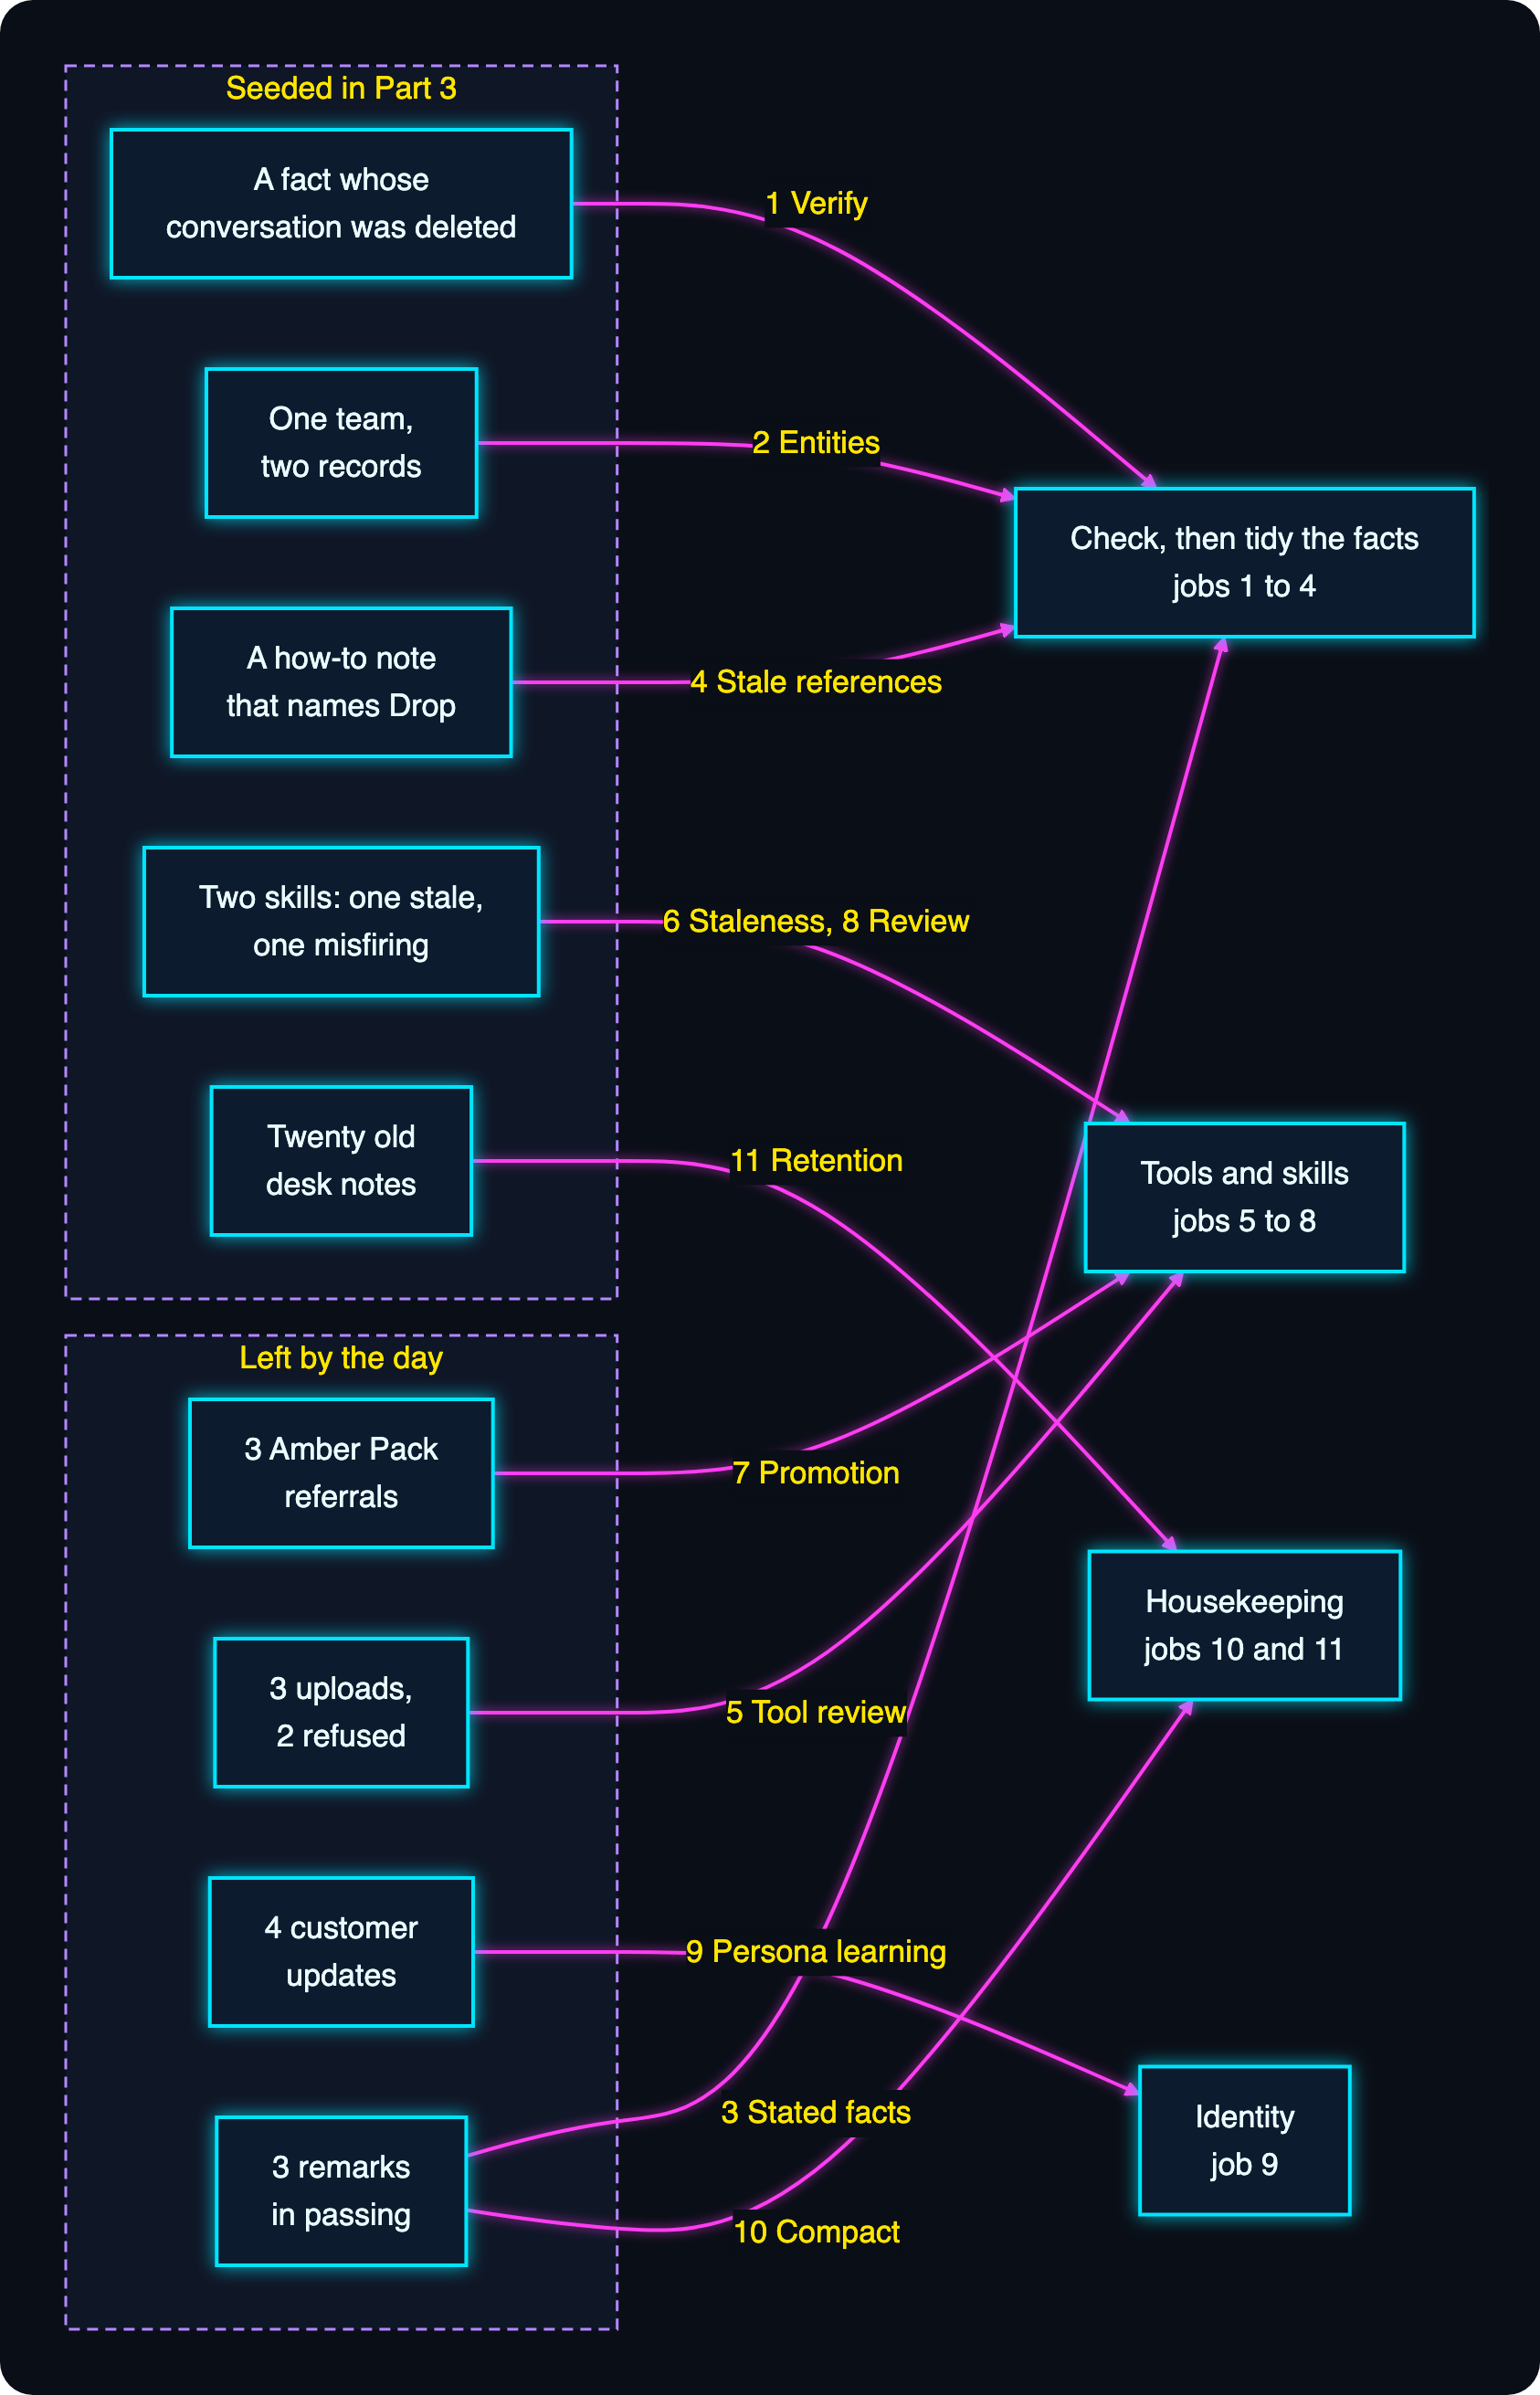

**How to read it.** The left-hand boxes are things *in memory or in the
transcripts*. The right-hand boxes are the cycle's jobs, in four groups.
Each arrow is labelled with the job that will pick that thing up.

| What is there | Where it came from | The job that finds it | What that job does |
|---|---|---|---|
| A fact whose conversation was deleted | Seeded (3d) | 1 · Verify notes | Flags it |
| One team, two records | Seeded (3a) | 2 · Entities | Merges them |
| Three remarks in passing | The day | 3 · Stated facts | Stores them, with Priya's words |
| A how-to note that names Drop | Seeded (3d) | 4 · Stale references | Flags it, once Drop's record changes |
| Three uploads, two refused | The day | 5 · Tool review | Proposes a usage note |
| A skill whose tool is gone | Seeded (3b) | 6 · Skill staleness | Deprecates it |
| Three Amber Pack referrals | The day | 7 · Promotion | Distils a skill, in shadow |
| A skill that misfires | Seeded (3b) | 8 · Skill review | Flags it |
| Four customer updates | The day | 9 · Persona learning | Proposes one sentence |
| The records jobs 2 and 3 changed | The cycle itself | 10 · Compact | Embeds them again |
| Twenty old desk notes | Seeded (3c) | 11 · Retention | Plans to retire them |

**The dataset: `DAY`.** Ten short conversations, fourteen messages, all
from Priya. Nothing in it is unusual; it is written so that every kind of
request leaves something behind for a different job.

| Group (the keys) | Conversations | What Priya asks | What it leaves for the cycle | The job it feeds |
|---|---|---|---|---|
| `amber-1` to `amber-3` | 3 | A fraud referral, in three different wordings | The **same three-step procedure, three times**, hiding in three run logs | Promotion |
| `upload-1` to `upload-3` | 3 | Attach a file: 40MB, 12MB, 31MB | **Two refusals** (BCN-217: over 25MB) and one success, in the run logs | Tool review |
| `update-1` to `update-4` | 4 | Draft a message to a customer about their claim | A **pattern of work** the persona doesn't mention yet | Persona learning |
| the second message of `update-2`, `-3`, `-4` | *(3 remarks)* | Her working days, her grade, "Drop has been retired" | Three **stated facts**: two new, one that **contradicts a record** | Stated facts, then Stale references |
| *(nothing — they were already there)* | | | The duplicate, the stale skill, the misfiring skill, the old notes, the unverifiable fact, the how-to note | Entities, Skill staleness, Skill review, Retention, Verify notes |

How to read one entry: the key is the conversation's name, and the list is
what Priya types, in order. `"update-2"` has two messages — a request, then
a follow-up in the same conversation:

| | In `update-2` | Why it is worded that way |
|---|---|---|
| Message 1 | "Customer update for CW-512131, still waiting on their photos (Q3). Keep it friendly." | The work: one of four customer updates. Q3 means Calderwood is waiting for the customer's documents |
| Message 2 | "Good. I work Tuesdays to Fridays, so say I'll call them on Tuesday." | A fact about Priya, said in passing. Nobody asked Ada to remember it |

What "right" looks like on the turn: a referral runs its three tools; a
12MB file attaches and a 40MB one is refused; a customer update is plain
English and never mentions Q9, the CFU or fraud. What "right" looks like
*overnight* is the fourth column.

In [19]:
DAY = {
    "amber-1": ["CW-512318 looks staged: the receipts are dated after the loss. Amber Pack it."],
    "amber-2": ["Please raise an Amber Pack on claim CW-512402, the same phone number is on three other claims."],
    "amber-3": ["Fraud referral needed for CW-512467: the invoice has been altered."],
    "upload-1": ["Attach the customer's 40MB video to CW-512533."],
    "upload-2": ["Put the customer's 12MB photo set on CW-512131."],
    "upload-3": ["Add the surveyor's 31MB drone footage to CW-512290."],
    "update-1": [
        "Draft a customer update for CW-512044: the surveyor's report is back and we're "
        "moving to settlement. Keep it in plain English.",
        "Shorter, and expand any abbreviations.",
    ],
    "update-2": [
        "Customer update for CW-512131, still waiting on their photos (Q3). Keep it friendly.",
        "Good. I work Tuesdays to Fridays, so say I'll call them on Tuesday.",
    ],
    "update-3": [
        "Write the customer update for CW-512207: payment released (Q12). Two sentences.",
        "I'm a Grade 2 handler, so I signed that payment off myself. Leave my grade out of the update.",
    ],
    "update-4": [
        "One more customer update, for CW-512290: we're waiting on the engineer's report (Q7). Same plain tone.",
        "And don't point them at Drop for the photos. Drop has been retired: Compass is the customer upload portal now.",
    ],
}
THREADS = [f"{thread}-{RUN}" for thread in DAY]
print(len(DAY), "conversations,", sum(len(messages) for messages in DAY.values()), "messages from Priya")

10 conversations, 14 messages from Priya


**Run the day.** Both agents get every message, word for word. Only Ada's
replies are printed; the twin's day is the same day.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.run(text, memory_id=…, user_id=…, thread_id=…)` | MemoRizz API | One turn: recall, model calls, tool calls, reply, and the write-back to memory | The three ids are the scope. Later, they are what lets the cycle say *whose* conversations it is allowed to read |
| `thread_id` | MemoRizz API | Which conversation a turn belongs to | Persona learning counts a pattern once per conversation, so four updates in four threads is four pieces of evidence |
| `wait_for_memory_upkeep(60)` | MemoRizz API | Blocks until the background writes from those turns have landed | Skip it and the next cell can read a store that is still being written |

**What to notice in the output:** the Amber Pack replies should mention the
referral; the customer updates should *not* mention Q9, the CFU or fraud.
Each `Tool execution failed: BCN-217` line is Beacon refusing a file over
25MB — it prints twice per refusal, once for Ada and once for her twin.
In the upload turns, watch what Ada suggests when Beacon refuses the big
files. She is carrying a skill and a note that both say *Drop* — and Priya
doesn't mention that Drop has gone until the very last message of the day.
And nowhere does Ada say "I'll remember that" and mean it — on the turn,
nothing is stored as a fact.

In [20]:
import time

started = time.time()
turns = 0
for thread, messages in DAY.items():
    for text in messages:
        scope = {"user_id": USER_ID, "thread_id": f"{thread}-{RUN}"}
        reply = agent.run(text, memory_id=MEMORY_ID, **scope)
        twin.run(text, memory_id=TWIN_MEMORY_ID, **scope)
        turns += 1
        print(f"[{thread}] Priya: {text[:62]}...")
        print(f"{'':<10} Ada  : {' '.join(str(reply).split())[:88]}")
agent.wait_for_memory_upkeep(60)
twin.wait_for_memory_upkeep(60)
print(f"\n{turns} turns each, for two agents, in {time.time() - started:.0f}s")

[amber-1] Priya: CW-512318 looks staged: the receipts are dated after the loss....
           Ada  : Amber Pack raised for CW-512318 and referred to the Counter Fraud Unit. The indicator re


[amber-2] Priya: Please raise an Amber Pack on claim CW-512402, the same phone ...
           Ada  : Amber Pack raised for **CW-512402**. Indicator recorded: the same phone number is associ


[amber-3] Priya: Fraud referral needed for CW-512467: the invoice has been alte...
           Ada  : Amber Pack raised for CW-512467 and referred to the Counter Fraud Unit. Indicator record


Tool execution failed: BCN-217: Beacon rejected an attachment over 25MB


Tool execution failed: BCN-217: Beacon rejected an attachment over 25MB


[upload-1] Priya: Attach the customer's 40MB video to CW-512533....
           Ada  : Beacon rejected the 40MB video (BCN-217), so it wasn’t attached. The limit is 25MB; plea


... (8 outputs left out)

[update-3] Priya: Write the customer update for CW-512207: payment released (Q12...
           Ada  : Your payment has now been released. Please allow some time for it to reach your account.


[update-3] Priya: I'm a Grade 2 handler, so I signed that payment off myself. Le...
           Ada  : Your payment has now been released. Please allow some time for it to reach your account.


[update-4] Priya: One more customer update, for CW-512290: we're waiting on the ...
           Ada  : We’re still waiting for the engineer’s report. We’ll update you once it’s come through a


[update-4] Priya: And don't point them at Drop for the photos. Drop has been ret...
           Ada  : Understood—I’ll direct customers to Compass for uploads, not Drop.

14 turns each, for two agents, in 160s


## 5 · Memory at five o'clock

Before we tidy anything, look at what the day actually left. We need three
small readers first. Each uses a read that is scoped to one agent, so
nothing here can see another notebook's Ada.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `provider.list_for_agent(MemoryType.X, agent_id)` | MemoRizz API | The records of one memory type that one agent wrote | A store is shared by every agent that uses it; this is the scoped read. (With the agent object in hand, `agent.learned_skills()` and `agent.workflow_runs()` do the same job; our helpers take an id, so they use the provider's version) |
| `MemoryType.SKILLBOX`, `WORKFLOW_MEMORY`, `KNOWLEDGE_BASE` | MemoRizz API | The stores for skills, for run logs, and for notes | Three of the things a cycle can change, promote from, or retire |
| `skills_of(agent_id)` | notebook helper | `(name, status)` for each of an agent's skills | Status is the thing to watch: `active`, `shadow`, `deprecated` |
| `workflows_of(agent_id)` | notebook helper | An agent's run logs | One per tool-using turn. The raw material for promotion |
| `live_notes(agent_id)` | notebook helper | An agent's desk notes that are not suppressed | `retention_state == "suppressed"` is how a retired note is marked. It is hidden, not deleted |

In [21]:
def skills_of(agent_id):
    """(name, status) of each skill that belongs to one agent."""
    rows = provider.list_for_agent(MemoryType.SKILLBOX, agent_id)
    return sorted((str(s.get("name")), str(s.get("status"))) for s in rows)


def workflows_of(agent_id):
    return provider.list_for_agent(MemoryType.WORKFLOW_MEMORY, agent_id)


def live_notes(agent_id):
    """Desk notes still in play: not suppressed by a retention plan."""
    rows = provider.list_for_agent(MemoryType.KNOWLEDGE_BASE, agent_id)
    return [n for n in rows if str(n.get("retention_state") or "") != "suppressed"]

**One snapshot of everything an agent knows.**

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `memory_snapshot(label, agent_id, memory_id)` | notebook helper | Prints the entities (each fact with its source level), the persona's version and goals, the skills and their status, and the counts of notes and run logs — and returns the lot as a JSON string | That string is a **fingerprint**. Compare two and you know whether *anything* changed, without reading either. It is how we'll prove a dry run wrote nothing |
| `source_level(attribute)` | MemoRizz API | The trust level of one fact: L3 host, L2 user, L1 consolidation | Printed beside every fact, so you can see who put it there |
| `entity_aliases(record)` | MemoRizz API | The other names a record answers to | Empty now. Not for long |
| `MemAgent.load(agent_id, memory_provider=…)` | MemoRizz API | Reloads the saved agent from the store | Reads the persona as it is *stored*, not as this Python object remembers it |

In [22]:
def memory_snapshot(label, agent_id=None, memory_id=None):
    """Print what one agent knows, and return it as a comparable fingerprint."""
    agent_id, memory_id = agent_id or AGENT_ID, memory_id or MEMORY_ID
    state = {"entities": [], "skills": skills_of(agent_id), "notes": len(live_notes(agent_id))}
    print(f"-- {label}")
    for record in entities.list_entities(memory_id=memory_id, user_id=USER_ID):
        facts = [f"{a['name']}={a.get('value')} (L{source_level(a)})" for a in record.get("attributes") or []]
        aliases = entity_aliases(record)
        print(f"   entity  {record['name']}" + (f"  also known as {aliases}" if aliases else ""))
        for fact in facts:
            print(f"             {fact}")
        state["entities"].append([record["name"], aliases, facts])
    persona = MemAgent.load(agent_id, memory_provider=provider).persona_manager.current_persona
    print(f"   persona v{persona.version}  goals: {persona.goals}")
    state["persona"] = [persona.version, persona.goals, persona.background, list(persona.guardrails)]
    for name, status in state["skills"]:
        print(f"   skill   {name} [{status}]")
    print(f"   notes in play: {state['notes']}   run logs: {len(workflows_of(agent_id))}")
    return json.dumps(state, sort_keys=True, default=str)

**Take the snapshot, for both.** Compare what prints with the "nine
o'clock" table in Part 1. It should be the same picture.

In [23]:
before = memory_snapshot("Ada, before the cycle")
twin_before = memory_snapshot("the twin, at the same moment", TWIN_ID, TWIN_MEMORY_ID)
print("\nidentical:", before == twin_before)

-- Ada, before the cycle
   entity  CFU
             led_by=Nadia Hussain (L2)
             office=Leeds (L2)
             amber_pack_deadline=2 working days (L2)
   entity  Counter Fraud Unit
             led_by=Nadia Hussain (L3)
             office=Manchester (L3)
             amber_pack_deadline=3 working days (L3)
   entity  Drop
             used_for=customer upload portal for large files (L2)
             status=in use (L2)
   entity  BCN-217
             meaning=Beacon rejected an attachment over 25MB (L3)
             fix=split the file, or ask the customer to send it through the customer upload portal (L3)
   entity  Marcus Webb
             desk=motor claims (L2)
   persona v1  goals: Help claims handlers resolve claims quickly and correctly.
   skill   Large attachment [active]
   skill   Put a claim on hold [active]
   notes in play: 21   run logs: 6
-- the twin, at the same moment
   entity  CFU
             led_by=Nadia Hussain (L2)
             office=Leeds (L2)
       

Fourteen turns in, and both memories are exactly as they were at nine
o'clock. Two records for one team, in two different cities, with two
different deadlines. A record that says Drop is in use, and a note that
agrees with it. A fact about Marcus that rests on nothing. Two active
skills, one of which calls a tool that isn't there. Persona at version 1.
Priya's working days and her grade are in a transcript and nowhere else.

The only thing that grew is the count of run logs: one per turn that used a
tool, which means one per Amber Pack and one per upload.

For Ada, that is the counters being off, doing their job. The work hasn't
been lost. It has been *deferred*. For the twin, it is simply how things
are, and how they will stay.

This is the last moment the two are the same.

# Part 5 · The night: the refine cycle

**What you'll learn here:** how to rehearse a cycle without writing
anything, how to read its report, what each of the eleven jobs did to Ada's
memory and why they run in the order they do, and which changes were
applied, which were only flagged, and which were left for a person. **By
the end** you'll have a tidied memory, a stored report, three flags and a
short queue of decisions.

### The cycle at a glance: what each job may do

Eleven jobs is a lot to hold in your head, so sort them by the one thing
that matters for trust: **what is each job allowed to do without a
person?** There are only three answers.

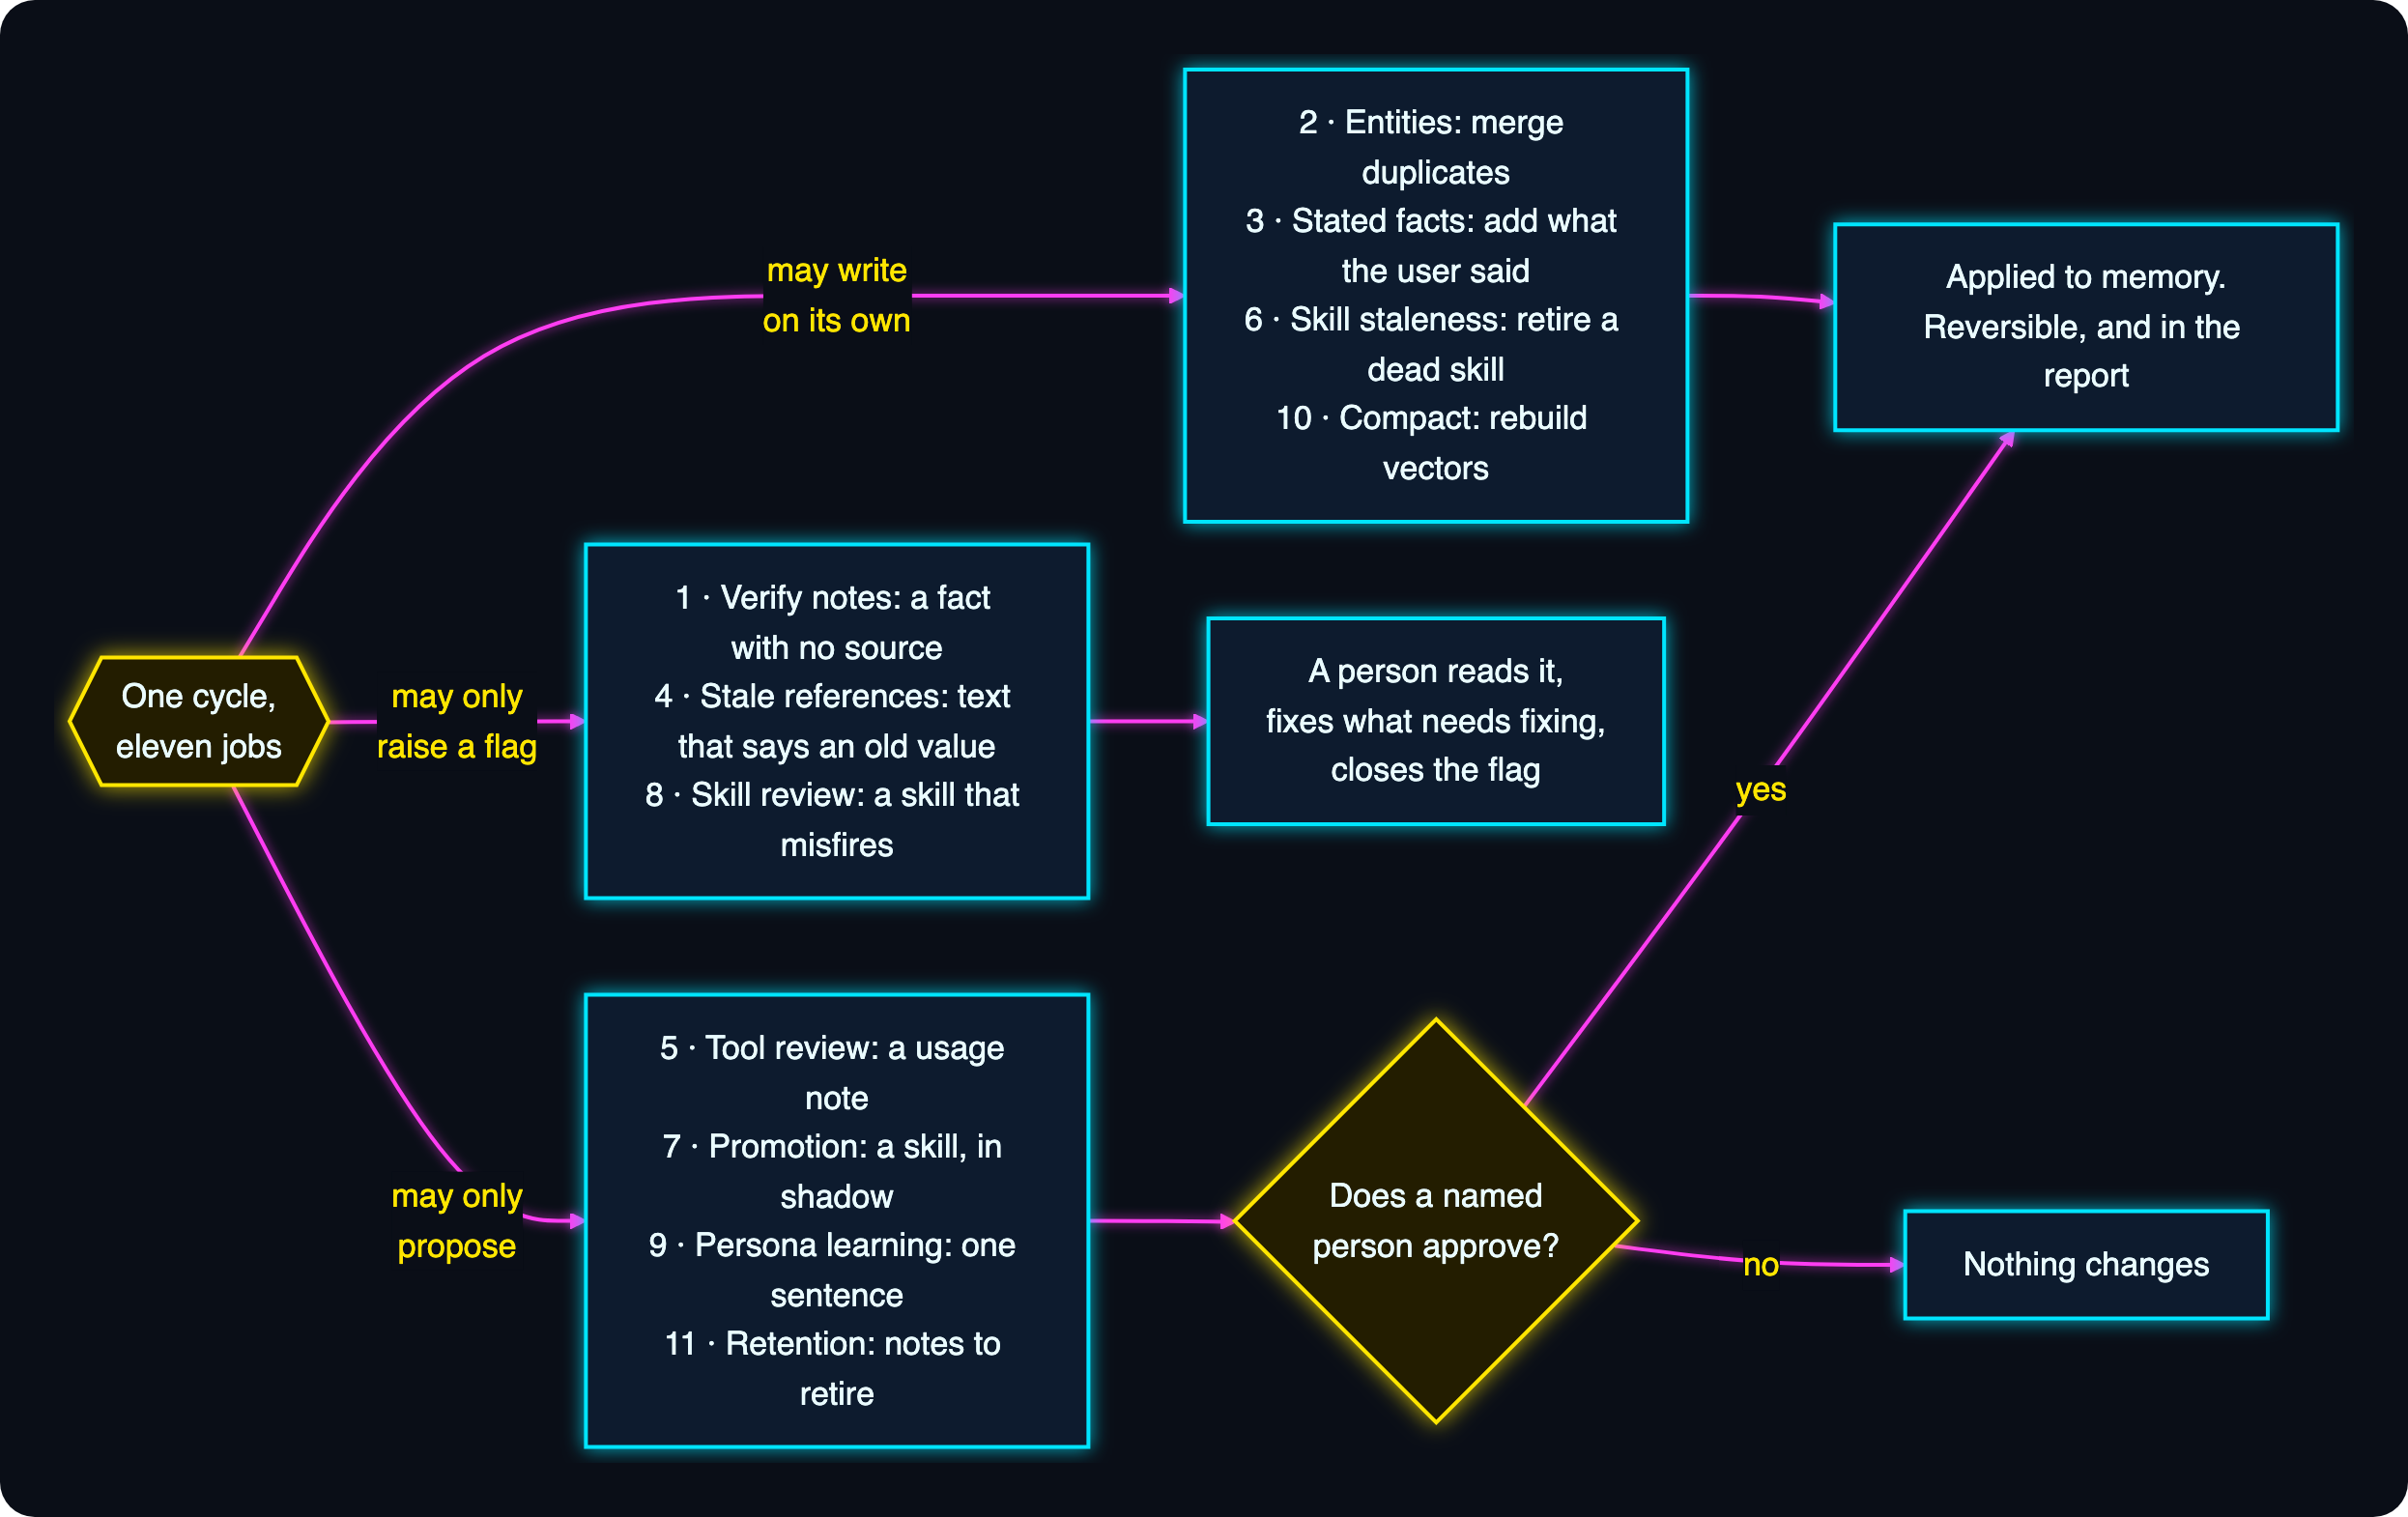

**How to read it.** Start at the left. Every job takes exactly one of the
three branches. The numbers are the order the jobs run in (1 first), and
the diamond is the only decision a person makes.

| Branch | Jobs | When a job is on this branch | How it ends |
|---|---|---|---|
| **May write on its own** | 2 Entities, 3 Stated facts, 6 Skill staleness, 10 Compact | The change is reversible and its settings allow it (2, 3), or there is nothing to decide: a skill whose tool is gone can't run (6), a vector can always be rebuilt (10) | Applied, and listed in the report with a `+` |
| **May only raise a flag** | 1 Verify notes, 4 Stale references, 8 Skill review | The job has noticed something it cannot judge | A person reads it, and resolves or dismisses the flag |
| **May only propose** | 5 Tool review, 7 Promotion, 9 Persona learning, 11 Retention | The change would alter what the model is told, or hide something | Waits. A named person approves it, or nothing changes |

(Where a job sits is set by the agent's own settings — `auto_apply`,
`require_shadow`, `refine_tool_review` — and this is where *ours* put them.
Section 8 comes back to that table.)

## 6 · Rehearse first: the dry run

**A dry run plans every job and applies nothing.** It is the cycle's
`--what-if`: each job does its reading and its reasoning, the report lists
what it *would* change, and the store is left alone.

We need a way to read a report. Every cycle returns the same shape, so one
small printer serves the dry run, the real run, and anything you later pull
out of the store.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `print_report(report)` | notebook helper | A headline, then one row per job, then one line per change | The same three levels the UI shows |
| `report["status"]`, `["trigger"]`, `["changed"]`, `["waiting"]`, `["tokens"]` | MemoRizz API | The headline of a cycle: how it ended, what started it, how many changes it recorded, how many are waiting for a person, what it cost | `tokens_estimated` says whether the count came from the model's own usage report or from the text |
| `report["jobs"]` | MemoRizz API | One entry per job, in order, each with `name`, `status`, `tokens`, `changes` (counts by kind), `items` and `notes` | Eleven entries, always, even when a job has nothing to do |
| `job["items"]` | MemoRizz API | The individual changes: `text` (what), `detail` (why), `applied` (whether it reached memory) | `+` and `·` in the printout are this flag |
| `job["notes"]` | MemoRizz API | Remarks for a person that aren't changes: how many notes verify read, why a tool wasn't revised | Printed under the table as `note [job]` |
| `report["pending"]` | MemoRizz API | What the cycle left for a person to **approve**: a `kind` and a `summary` each | The review queue. Flags are not in it: a flag is something to read, not a plan to approve |

The *changes* column is counts by kind, and the names are regular enough to
read once you know the pattern:

| You'll see | Job | It means |
|---|---|---|
| `flagged_source_missing`, `flagged_unsupported`, `flagged_source_sealed` | verify | A stored fact whose conversation is gone, doesn't say it, or was sealed |
| `merge_entities`, `add_fact`, `reinforce_fact`, `fact_not_applied` | entities, stated facts | Records merged; facts added; a stored fact the user said again; a remark kept beside a stronger value |
| `flagged_note`, `flagged_skill`, `closed` | propagation | A note or skill that still states a replaced value; a flag closed because the text was fixed |
| `planned_tool_revisions`, `tool_revisions`, `usage_flags` | toolbox | Revisions proposed (waiting) or applied; tools that are offered and never called |
| `deprecated`, `promoted`, `review_flags` | the three skill jobs | A skill retired, a skill distilled, a skill pointed at |
| `planned_persona_additions`, `planned_standing_rules` | persona learning | A goals sentence, or a standing rule, waiting for its owner |
| `re_embed_entities`, `re_embed_notes` | compact | Records whose vectors were rebuilt |
| `planned_suppressions` | retention | Notes that could be retired |
| a `would_` or `planned_` prefix | any, in a dry run | What the job *would* do. Nothing was written |

In [24]:
def print_report(report):
    """A refine report: a headline, one row per job, then one line per change."""
    kind = "DRY RUN" if report["dry_run"] else "CYCLE"
    estimated = " (estimated)" if report["tokens_estimated"] else ""
    print(f"{kind}  status={report['status']}  trigger={report['trigger']}  changed={report['changed']}  "
          f"waiting={report['waiting']}  tokens={report['tokens']}{estimated}")
    print(f"\n  {'#':<3}{'job':<18}{'status':<9}{'tokens':>7}  changes")
    for number, job in enumerate(report["jobs"], 1):
        changes = ", ".join(f"{k}: {v}" for k, v in job["changes"].items()) or "nothing to do"
        print(f"  {number:<3}{job['name']:<18}{job['status']:<9}{job['tokens']:>7}  {changes}")
    print("\n  + applied   · not applied")
    for job in report["jobs"]:
        for item in job["items"]:
            print(f"  {'+' if item['applied'] else '·'} [{job['name']}] {item['text']}")
            if item.get("detail"):
                print(f"      why: {item['detail'][:150]}")
    for job in report["jobs"]:
        for note in job["notes"]:
            print(f"  note [{job['name']}] {note[:150]}")
    for plan in report["pending"]:
        print(f"  waiting for a person: {plan['kind']}: {plan['summary']}")

**Now the rehearsal itself.** One call.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.refine(dry_run=True, memory_id=…, user_id=…)` | MemoRizz API | Runs all eleven jobs in order for one memory and one user, and returns the report. With `dry_run=True`, every job plans and none writes | The scope is the permission: this cycle may read Priya's conversations in Ada's memory, and nothing else |

**What to notice in the output:** nine of the eleven jobs should have
something in the *changes* column, every count should carry a `would_` or
`planned_` prefix, and every change line should start with `·`. The two
with "nothing to do" are *propagation* and *compact*, and that is correct —
the next cell's notes say why.

In [25]:
dry = agent.refine(dry_run=True, memory_id=MEMORY_ID, user_id=USER_ID)
print_report(dry)

DRY RUN  status=dry_run  trigger=manual  changed=26  waiting=0  tokens=8140

  #  job               status    tokens  changes
  1  verify            done           0  would_flag_source_missing: 1
  2  entities          done        6285  planned_merge_entities: 1
  3  stated_facts      done           0  planned_add_fact: 4
  4  propagation       done           0  nothing to do
  5  toolbox           done         855  planned_tool_revisions: 1
  6  skill_staleness   done           0  planned_deprecations: 1
  7  promotion         done           0  eligible_classes: 1
  8  skill_review      done           0  review_flags: 1
  9  persona_learning  done        1000  planned_persona_additions: 1
  10 compact           done           0  nothing to do
  11 retention         done           0  planned_suppressions: 15

  + applied   · not applied
  · [verify] Marcus Webb.desk = motor claims
      why: The conversation it came from is gone
  · [entities] Merged Counter Fraud Unit and CFU
      wh

Read it top to bottom; it is the whole day — and the whole autumn —
reorganised on paper.

- **Verify** would flag the fact about Marcus: the conversation it cites
  isn't there.
- **Entities** would merge the two records for the fraud team.
- **Stated facts** would add what Priya said, each with the words it rests
  on. A fact with no quote from the user is dropped before it ever reaches
  the report.
- **Propagation** has nothing to rehearse. It looks for text that states a
  value the entity jobs *have replaced* — and in a dry run they haven't
  replaced anything yet.
- **Tool review** would propose a revision to the upload tool: two refusals
  for the same reason is a pattern, and a pattern belongs in the tool's
  description.
- **Skill staleness** would deprecate *Large attachment*: one of its tools
  no longer resolves.
- **Promotion** found one class of run that passes its gates: the Amber
  Pack referral, three runs, three different wordings.
- **Skill review** flags *Put a claim on hold*: loaded eight times,
  followed twice.
- **Persona learning** would add one sentence to Ada's goals, and shows
  the separate conversations it found the pattern in.
- **Compact** has nothing to rehearse either, for the same reason as
  propagation: it re-embeds what changed, and nothing has.
- **Retention** counts the old notes that could be retired. It may well be
  fewer than twenty — hold that thought for section 10.

Every line is marked `·`: not applied. Don't trust the mark. Check.

In [26]:
after_dry_run = memory_snapshot("Ada, after the dry run")
assert after_dry_run == before, "a dry run must not change memory"
print("\nUnchanged: the dry run wrote nothing to entities, persona, skills or notes.")
print("Tokens it spent thinking about it:", dry["tokens"])

-- Ada, after the dry run
   entity  CFU
             led_by=Nadia Hussain (L2)
             office=Leeds (L2)
             amber_pack_deadline=2 working days (L2)
   entity  Counter Fraud Unit
             led_by=Nadia Hussain (L3)
             office=Manchester (L3)
             amber_pack_deadline=3 working days (L3)
   entity  Drop
             used_for=customer upload portal for large files (L2)
             status=in use (L2)
   entity  BCN-217
             meaning=Beacon rejected an attachment over 25MB (L3)
             fix=split the file, or ask the customer to send it through the customer upload portal (L3)
   entity  Marcus Webb
             desk=motor claims (L2)
   persona v1  goals: Help claims handlers resolve claims quickly and correctly.
   skill   Large attachment [active]
   skill   Put a claim on hold [active]
   notes in play: 21   run logs: 6

Unchanged: the dry run wrote nothing to entities, persona, skills or notes.
Tokens it spent thinking about it: 8140


Three things worth noticing.

**A dry run isn't free.** It spends real tokens on the background model,
because the planning *is* the model call. What it skips is the writing —
and, for promotion, the distillation of the skill itself, which is why the
real cycle below costs more.

**A dry run can't rehearse a consequence.** Propagation and compact act on
what the earlier jobs *change*. A rehearsal changes nothing, so those two
report nothing. Read their rows in the real cycle instead.

**A dry run is a rehearsal, not a contract.** The real cycle plans afresh,
with a fresh model call, so it can differ from the rehearsal by a line —
a differently worded persona sentence, a fact the model judged too slight
to keep the second time. What does not vary is what each job is *allowed*
to do.

**A dry run doesn't use up a review.** Persona learning normally skips a
review when nothing is new since the last one. If a rehearsal counted as
that review, the real cycle would arrive to find the work "already done".
It doesn't count, so it isn't.

## 7 · The real cycle

Same call, without the flag. This is the only cell in the notebook that
changes Ada's memory without a person's name attached — and, as section 8
shows, it only changes the parts her settings said it could.

In [27]:
started = time.time()
report = agent.refine(memory_id=MEMORY_ID, user_id=USER_ID)
print(f"(the cycle took {time.time() - started:.0f}s, on the background model)\n")
print_report(report)

(the cycle took 52s, on the background model)

CYCLE  status=done  trigger=manual  changed=32  waiting=4  tokens=11438

  #  job               status    tokens  changes
  1  verify            done           0  flagged_source_missing: 1
  2  entities          done        6315  merge_entities: 1
  3  stated_facts      done           0  add_fact: 5
  4  propagation       done           0  flagged_note: 1
  5  toolbox           done         903  planned_tool_revisions: 1
  6  skill_staleness   done           0  deprecated: 1
  7  promotion         done        3259  promoted: 1
  8  skill_review      done           0  review_flags: 1
  9  persona_learning  done         961  planned_persona_additions: 1
  10 compact           done           0  re_embed_entities: 4
  11 retention         done           0  planned_suppressions: 15

  + applied   · not applied
  · [verify] Marcus Webb.desk = motor claims
      why: The conversation it came from is gone
  + [entities] Merged Counter Fraud Unit a

**Now look at memory again.** Same snapshot, same function. Compare it,
line by line, with the one from five o'clock.

In [28]:
after = memory_snapshot("Ada, after the cycle")
assert after != before, "the cycle should have changed something"

-- Ada, after the cycle
   entity  Counter Fraud Unit  also known as ['CFU']
             led_by=Nadia Hussain (L3)
             office=Manchester (L3)
             amber_pack_deadline=3 working days (L3)
   entity  Drop
             used_for=customer upload portal for large files (L2)
             status=retired (L1)
   entity  BCN-217
             meaning=Beacon rejected an attachment over 25MB (L3)
             fix=split the file, or ask the customer to send it through the customer upload portal (L3)
   entity  Marcus Webb
             desk=motor claims (L2)
   entity  user
             work_schedule=Tuesdays to Fridays (L1)
             role=Grade 2 handler (L1)
             customer_update_tone=plain (L1)
   entity  compass
             used_for=customer upload portal (L1)
   persona v1  goals: Help claims handlers resolve claims quickly and correctly.
   skill   Large attachment [deprecated]
   skill   Put a claim on hold [active]
   skill   Raise an Amber Pack [shadow]
   notes 

**One job left no trace in that snapshot: compact.** The snapshot prints
text, and compaction never changes text. It rebuilds **vectors**.

Every entity record is stored with an *embedding* — a list of numbers built
from its name and current values — and semantic search finds a record by
comparing that list with the question's. Change a record's values and
leave its vector alone, and search keeps finding it for what it *used* to
say. So the cycle's tenth job embeds again every record that changed since
the cycle started. Earlier and retired values are never in the new vector.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `job_of(report, name)` | notebook helper | One job's entry in a report, by name | Used from here on, instead of counting positions in a list of eleven |
| `entities.embedding_report(record)` | MemoRizz API | Says whether a record's vector covers all of it: `full`, `partial` or `missing` | A check you can run on any record, whether or not a cycle has |

**What to notice in the output:** the records listed are exactly the ones
the entity jobs touched — the merged fraud team, `Drop`, anything new about
Priya. `BCN-217` and Marcus didn't change, so they weren't embedded again.

In [29]:
def job_of(report, name):
    """One job's entry in a refine report, by name."""
    return next(job for job in report["jobs"] if job["name"] == name)


print("embedded again by the compact job:")
for item in job_of(report, "compact")["items"]:
    print(f"  {item['text']:<40} because {item['detail']}")

print("\nvector status of each live record:")
for record in entities.list_entities(memory_id=MEMORY_ID, user_id=USER_ID):
    print(f"  {record['name']:<22}{entities.embedding_report(record)['status']}")

embedded again by the compact job:
  Embedded Counter Fraud Unit again        because it changed in this cycle
  Embedded Drop again                      because it changed in this cycle
  Embedded user again                      because it changed in this cycle
  Embedded compass again                   because it changed in this cycle

vector status of each live record:
  Counter Fraud Unit    full
  Drop                  full
  BCN-217               full
  Marcus Webb           full
  user                  full
  compass               full


That report is not only something a notebook can print. It is stored, and
the local UI reads the same record. This is the cycle above as an operator
sees it, on *Continual learning → Control plane → Refine cycles* (Part 7
shows how to open it on your own run):

![The list of refine cycles on the Learning control plane, with this cycle opened to show each change, the reason for it, and whether it was applied or is waiting for review](images/05_refine_cycle_report.png)

*The cycle, opened in the control plane's list of cycles: when it ran, who
started it, how many changes, how many are waiting, what it cost — then
every change as a line with the job that made it and the evidence behind
it. The rehearsal sits in the row below. The screenshots in this notebook
are from the run whose outputs are saved here.*

### The eleven jobs, and why they run in this order

| # | Job (`name`) | What it runs | Why it sits here | What it found today |
|---|---|---|---|---|
| 1 | **Verify notes** (`verify`) | Check stored facts against the conversations they cite; flag what isn't supported | First, so no later job builds on a note its source no longer backs | Marcus's desk: the conversation is gone |
| 2 | **Entities** (`entities`) | Merge duplicates and review attributes, under the source rule | Everything after it should read one record per thing | "CFU" and "Counter Fraud Unit" |
| 3 | **Stated facts** (`stated_facts`) | Add facts the user stated, each quoted from the transcript | New facts land on the merged record, not on a duplicate | Priya's remarks, including Drop's retirement |
| 4 | **Stale references** (`propagation`) | Flag the skills and notes that still state a value jobs 2 and 3 replaced | Straight after the entity jobs: that is when values change | The how-to note that says Drop is in use |
| 5 | **Tool review** (`toolbox`) | Read how tools were called; propose revisions to their descriptions | It reads the same run logs promotion is about to distil, so a tool problem is seen before a procedure is built on it | Two BCN-217 refusals on the upload tool |
| 6 | **Skill staleness** (`skill_staleness`) | Deprecate active skills whose tools no longer resolve | Don't promote next to, or measure, something already dead | *Large attachment* and `drop_send_link` |
| 7 | **Promotion** (`promotion`) | Gates, ranking, distillation and validation | Runs against a skill list that has just been cleaned | Three Amber Pack runs |
| 8 | **Skill review** (`skill_review`) | The deviation flag, the holdout flag, and skills with an open stale reference | Reviews the skills that survived 6 and 7 | *Put a claim on hold*, 6 of 8 |
| 9 | **Persona learning** (`persona_learning`) | Propose one sentence about the agent's work (and, if switched on, standing rules) | Reads entity facts as context — after they've been tidied | Four customer updates |
| 10 | **Compact and re-embed** (`compact`) | Embed again what changed, so vectors match the text | After everything that edits text | The records jobs 2 and 3 touched |
| 11 | **Retention** (`retention`) | A plan for what could be suppressed | Last, so it plans against memory as the cycle left it | The autumn's desk notes |

Jobs 2 and 3 come from **one consolidation plan** per memory, so the store
is read once. That is why the token count sits on *entities* and *stated
facts* shows zero: one model conversation, reported as two jobs.

Seven of these edit memory, or plan to. **Four don't touch its text at
all**, and they are the four that make the other seven safe to trust:

- **Verify** asks whether what memory *already holds* still has a source.
- **Stale references** asks what *else* was written on the strength of a
  value that has just changed.
- **Tool review** asks whether the tools' own descriptions are the reason
  calls keep failing.
- **Compact** makes sure search is reading the same memory you are.

Now match the table to what just happened to Ada:

- **The duplicate is gone.** One record for the fraud team, and the name it
  lost is kept as an **alias** — so a later mention of either name finds the
  same record. Nothing was deleted; the merged-away record is marked
  superseded and the merge can be undone.
- **The stronger source won, twice.** The two records disagreed about the
  office *and* the deadline. The merged record says Manchester and 3
  working days, both at level 3: the handbook's values outrank what a
  conversation said, however the two happened to be ordered. This is the
  January rule change arriving in Ada's answers without anyone editing a
  prompt.
- **Priya's facts are stored**, at level 1 — the *least* trusted level,
  because consolidation wrote them. If the host later states otherwise, the
  host wins. Look at the `Drop` record in particular: its `status` was a
  level-2 value from an old conversation, and a newer statement from the
  user replaced it. (The model decides what counts as a durable fact, and it
  doesn't keep exactly the same ones every run: one run stores Priya's
  working days, the next skips them and keeps her tone preference instead.
  Occasionally it keeps something it shouldn't — a detail of one claim,
  which is episodic and belongs in the transcript. The *rule* — no quote, no
  fact — doesn't vary, every fact it writes is level 1, and the whole plan
  can be undone with `agent.restore_memory_consolidation`.)
- **The fact about Marcus is flagged, and still there.** Verify doesn't
  delete what it can't check. It tells a person that one fact in memory has
  lost its evidence.
- **The how-to note is flagged, and still says Drop.** This is the line to
  read twice. Job 3 changed `Drop`'s status because Priya said so. Job 4
  then went looking for anything else that still says the old thing, found
  the note, and *left it exactly as it was*. A cycle that rewrote people's
  notes on the strength of one remark would be a cycle nobody could trust.
  (If this run's model didn't record Drop's retirement as a change to the
  `Drop` record, job 4 has nothing to find, and says so.)
- **The upload tool has a proposed revision.** Its catalogue entry is
  unchanged. The proposal — a usage note about the 25MB limit — is in the
  waiting list.
- **The stale skill is deprecated.** Not deleted: its status changed and
  the reason is recorded. It will no longer be loaded.
- **A new skill exists, in shadow** — if this run's distillation passed
  validation. (Distillation is a model call followed by a strict check and
  a judge; a draft that fails is rejected and the class stays eligible for
  the next cycle. The report says which happened.)
- **The misfiring skill is flagged, and untouched.** Skill review never
  changes anything. It tells a person.
- **The persona did not change.** A proposal exists. Version is still 1.
- **The changed records were embedded again.** Invisible in the snapshot,
  listed in the cell above.
- **No note was retired.** A plan exists.

## 8 · Each job keeps its own apply rule

This is the part that matters most for trusting the thing. **The cycle
changes when the jobs run and in what order. It does not change what any
job is allowed to do.**

| Job | Applies itself when | Otherwise |
|---|---|---|
| Verify notes | never — it only opens a flag | a person resolves or dismisses it |
| Entities, stated facts | consolidation `auto_apply` is on | the plan waits for review |
| Stale references | never — it opens a flag, and closes one whose text someone fixed | a person fixes the text |
| Tool review | `refine_tool_review` is `"auto"` | each revision waits (`"propose"`, the default) |
| Skill staleness | always — a skill whose tool is gone cannot run | — |
| Promotion | `require_shadow` is off | the skill waits in shadow for activation |
| Skill review | never — it only raises flags | a person decides |
| Persona learning | persona `auto_apply` is on, for a goals sentence. A standing rule never applies itself | the proposal waits for review |
| Compact and re-embed | always — it writes vectors and changes no text | — |
| Retention | never | always waits for a named person |
| **Guardrails** | **never, by any job** | only host code or an operator may change them |

So the report has three kinds of line: what was written, what is `waiting`
for a person to approve, and what was only flagged for a person to read.
(One wrinkle: the headline `changed` figure counts every change a job
recorded, including one it proposed, flagged or noted without applying —
and retention counts each candidate note. The `+` and `·` marks are what tell
you which lines actually reached memory, which is why the next cell counts
them itself.)

Let's verify the last row of the table rather than assert it in prose.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `persona.guardrails` | MemoRizz API | The persona's rules, as stored (read through `MemAgent.load`, as in the snapshot) | Compared with the list we wrote in section 2. An `assert`, not a hope |
| `item["applied"]`, `report["waiting"]`, `report["pending"]` | MemoRizz API | Covered in section 6 | Here we count them ourselves, so the two halves of the report are numbers, not marks |

In [30]:
stored_guardrails = list(MemAgent.load(AGENT_ID, memory_provider=provider).persona_manager.current_persona.guardrails)
assert stored_guardrails == GUARDRAILS, "no learning path may write guardrails"
print("Guardrails after the cycle (unchanged):")
for number, rule in enumerate(stored_guardrails, 1):
    print(f"  {number}. {rule}")

lines = [item for job in report["jobs"] for item in job["items"]]
print(f"\nwritten by the cycle : {sum(1 for item in lines if item['applied'])} change(s)")
print(f"noted, not written   : {sum(1 for item in lines if not item['applied'])}")
print(f"waiting for a person : {report['waiting']} item(s)")
for plan in report["pending"]:
    print(f"  - {plan['kind']:<17} {plan['summary']}")

Guardrails after the cycle (unchanged):
  1. Never give a customer a coverage decision.
  2. Never tell a customer the reason a payment was frozen.

written by the cycle : 12 change(s)
noted, not written   : 6
waiting for a person : 4 item(s)
  - tool_revision     A revision of tool beacon_upload_attachment to review
  - skill_activation  Skill Raise an Amber Pack is in shadow, waiting for activation
  - persona           A persona change to review
  - retention         15 memory record(s) could be suppressed


## 9 · The report is a record, not a log line

Every cycle stores one `RefineRun`. It outlives the process that made it —
which matters, because the person who reviews what the cycle left is rarely
the process that ran it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.refine_runs()` | MemoRizz API | The agent's stored cycles, newest first, each in the same shape `refine()` returned | The dry run is in there too. A rehearsal is still something that happened |
| `run["started_at"]`, `job["seconds"]`, `job["tokens_estimated"]` | MemoRizz API | When a cycle ran, how long each job took, and whether its token count was measured or estimated | Enough to answer "what did last night cost, and where did it go?" |

In [31]:
for run in agent.refine_runs():
    kind = "dry run" if run["dry_run"] else "cycle  "
    print(f"{run['started_at'][:19]}  {kind}  status={run['status']:<8} changed={run['changed']}  "
          f"waiting={run['waiting']}  tokens={run['tokens']}")

stored = agent.refine_runs()[0]
print("\ntokens by job (real cycle):")
for job in stored["jobs"]:
    if job["tokens"]:
        note = " (estimated)" if job["tokens_estimated"] else ""
        print(f"  {job['name']:<18}{job['tokens']:>6}{note}  in {job['seconds']:.1f}s")

2026-11-12T15:22:33  cycle    status=done     changed=32  waiting=4  tokens=11438
2026-11-12T15:21:50  dry run  status=dry_run  changed=26  waiting=0  tokens=8140

tokens by job (real cycle):
  entities            6315  in 32.9s
  toolbox              903  in 3.2s
  promotion           3259  in 11.7s
  persona_learning     961  in 4.1s


Most of the eleven jobs cost nothing. Staleness, skill review, propagation
and retention are arithmetic and string matching over records that already
exist; stated facts share their model conversation with entities; compact
makes embedding calls, which are not counted here; and verify stayed in
code, because a missing conversation needs no model to spot. (It asks the
background model only when a conversation exists but doesn't obviously
contain the fact, at most three times a cycle.) The tokens went on the jobs
that have to *read*: the consolidation plan, the tool review, the
distillation, the persona review.

Each job's `items` are the lines printed above: what it did, why, and
whether it was applied. They quote memory content, so the MCP tools leave
them out; the local UI shows them under *What changed*.

# Part 6 · The morning: clear the queue, set the clock, compare

**What you'll learn here:** how a person approves — or declines — what the
cycle left waiting, what to do with a flag, how to undo an approval, how to
put the cycle on a schedule, and whether any of it made a difference to an
answer. **By the end** you'll have a persona at a new version, an activated
skill, a revised tool, two flags closed by a named person, a retention plan
applied (and partly reversed), a scheduled job, and Ada and her twin
answering the same three questions.

## 10 · Clear the queue

The cycle left two kinds of thing for a person, and they are handled
differently:

| | What it is | What a person does | In this run |
|---|---|---|---|
| **Waiting** (`report["pending"]`) | A change the cycle planned and was not allowed to make | Approves it, or doesn't | A persona sentence, a shadow skill, a tool revision, a retention plan |
| **Flagged** | Something the cycle noticed and can't judge | Reads it, fixes what needs fixing, closes the flag | A fact with no source, a note that names Drop |

At Calderwood, different people own different decisions, so we'll sign each
one with the right name: a **Desk Lead** (Dev) approves changes to what Ada
is for; a **Senior Handler** (Gwen) approves skills, tools and plans, and
deals with the flags.

**The persona proposal** is one sentence, with the quotes it rests on. The
code — not the model — found each quote word for word in a different
conversation before the proposal was allowed to exist.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.persona_learning_status()` | MemoRizz API | The state of persona learning: the last review, and the proposal `pending`, if there is one | A proposal carries its `field`, the `addition`, and `evidence` — a quote and a `thread_id` each |
| `agent.apply_persona_proposal(approved_by=…)` | MemoRizz API | Applies the waiting proposal and records who approved it | The persona's version goes up by one, and the change can be undone with `undo_persona_change` |

In [32]:
status = agent.persona_learning_status()
proposal = status["pending"]
if proposal:
    print(f"Proposed addition to persona.{proposal['field']}:")
    print(f"  \"{proposal['addition']}\"")
    print("Evidence (Priya's own words, one conversation each):")
    for quote in proposal["evidence"]:
        print(f"  - {quote['thread_id'].rsplit('-', 1)[0]:<10} \"{quote['quote']}\"")
    agent.apply_persona_proposal(approved_by="dev")
    persona = MemAgent.load(AGENT_ID, memory_provider=provider).persona_manager.current_persona
    print(f"\nApproved by dev (Desk Lead). Persona is now v{persona.version}.")
    print("goals:", persona.goals)
    assert list(persona.guardrails) == GUARDRAILS
else:
    print("No persona proposal is waiting:", status["last_review"])

Proposed addition to persona.goals:
  "Draft clear, plain-language customer updates about claim progress."
Evidence (Priya's own words, one conversation each):
  - update-4   "One more customer update"
  - update-3   "Write the customer update"
  - update-1   "Draft a customer update"



Approved by dev (Desk Lead). Persona is now v2.
goals: Help claims handlers resolve claims quickly and correctly. Draft clear, plain-language customer updates about claim progress.


**The shadow skill** is the Amber Pack referral, distilled. Read it before
activating it — that is the whole point of shadow. It should describe the
*shape* of the procedure (look up, mark referred, raise the pack) and none
of today's claim references or the indicators Priya typed; validation
rejects a skill that leaks a literal value from the runs it was distilled
from.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `skillbox.list_skills()` | MemoRizz API | The agent's skills as `Skill` objects | We pick out the one whose status is `shadow` |
| `skill.content`, `skill.tools_used`, `skill.description` | MemoRizz API | The `SKILL.md`, the tools it depends on, and when to use it | What a reviewer reads |
| `manager.activate_skill(skill_id)` | MemoRizz API | Approves a shadow skill: from now on it is loaded for matching requests | The step `require_shadow=True` made mandatory |
| `manager.run_promotion_cycle(user_id=…)` | MemoRizz API | The promotion job on its own: gates, distillation, validation, judge | Used only if last night's draft was rejected. A rejected class stays eligible, so the next cycle tries again; we ask for that attempt now rather than wait a night |

**If the report said `rejected`.** Distillation is a model writing a
procedure, then code checking it, then a second model call judging it
against the runs. The judge is strict and it varies: the same three runs
can pass one night and fail the next on a quibble. A rejection costs
nothing but the tokens — no skill is created — and the cell below makes up
to two more attempts, which is what the next two nights would have done.

In [33]:
manager = agent.continual_learning_manager
in_shadow = lambda: [s for s in manager.skillbox.list_skills() if s.status.value == "shadow"]
shadow, attempt = in_shadow(), 1
while not shadow and attempt < 3:
    attempt += 1
    again = manager.run_promotion_cycle(user_id=USER_ID)
    print(f"promotion, attempt {attempt}: promoted {len(again.promoted)}, rejected {len(again.rejected)}")
    shadow = in_shadow()
if shadow:
    skill = shadow[0]
    print(f"{skill.name}  [{skill.status.value}]  tools: {skill.tools_used}")
    print(f"when to use: {skill.description}\n")
    print(skill.content[:800])
    leaked = [ref for ref in ("512318", "512402", "512467", "receipts", "phone number", "invoice") if ref in skill.content]
    print("\nliteral values from today's runs in the skill:", leaked or "none")
    manager.activate_skill(skill.skill_id)
    print("activated by gwen (Senior Handler); status:", manager.skillbox.get_skill_by_id(skill.skill_id).status.value)
else:
    print("No skill is waiting in shadow; promotion reported:", job_of(report, "promotion")["changes"])

Raise an Amber Pack  [shadow]  tools: ['beacon_lookup_claim', 'beacon_refer_to_cfu', 'raise_amber_pack']
when to use: Use this skill when a user requests a fraud referral or Amber Pack for a claim and provides a suspected fraud indicator.

---
name: Raise an Amber Pack
description: Use this skill when a user requests a fraud referral or Amber Pack for a claim and provides a suspected fraud indicator.
preconditions:
  - The request identifies a claim reference.
  - The request describes a suspected fraud indicator.
  - The user requests a fraud referral or an Amber Pack.
tools: [beacon_lookup_claim, beacon_refer_to_cfu, raise_amber_pack]
---

# Raise an Amber Pack

## When to apply
Apply when the user requests a fraud referral or Amber Pack for an identified claim and describes a suspected fraud indicator. When NOT to apply: do not use this procedure if there is no claim reference, no suspected fraud indicator, or no request for a fraud referral or Amber Pack.

## Procedure
1. Call `bea

**The tool revision** is the cycle's proposal for the upload tool. Twice
today Ada called `beacon_upload_attachment` with a file over 25MB, and
twice Beacon said BCN-217. Nothing in the tool's description warned her.
The tool review read both failures and proposed a **usage note**: one line,
added under the description the author wrote, telling the model what the
tool will refuse. (Notebook 04 is the long version, including what the code
checks before a note is allowed: it must rest on at least two failed calls
and may not contain an argument value from them.)

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.tool_revisions()` | MemoRizz API | Every revision proposed for this agent's tools, newest first, each with its `status` | We pick out the ones the cycle left `proposed` |
| `revision.notes_added`, `.avoid_added`, `.queries_added` | MemoRizz API | What the revision would add: usage notes, "not for this; use that" lines, example requests | Read before approving. This is the text the model will see |
| `revision.evidence` | MemoRizz API | The calls it rests on: the request and the error, never the argument values | Why the proposal exists |
| `agent.apply_tool_revision(revision_id, approved_by=…)` | MemoRizz API | Writes the revision to the tool's catalogue entry and records who approved it | Undone with `agent.undo_tool_revision(tool, approved_by=…)` |

**What to notice in the output:** the note is about the *tool* (a limit),
not about today's claims or files.

In [34]:
proposed = {revision.revision_id: revision for revision in agent.tool_revisions() if revision.status == "proposed"}
waiting_tools = [plan for plan in report["pending"] if plan["kind"] == "tool_revision"]
for plan in waiting_tools:
    revision = proposed[plan["plan_id"]]
    print(f"{revision.tool}: a revision resting on {len(revision.evidence)} call(s)")
    for line in revision.notes_added + revision.avoid_added:
        print("  + usage note :", line)
    for line in revision.queries_added:
        print("  + example    :", line)
    for call in revision.evidence[:2]:
        print(f"  evidence     : {str(call.get('query'))[:52]!r} -> {str(call.get('error'))[:60]}")
    applied = agent.apply_tool_revision(revision.revision_id, approved_by="gwen")
    print(f"  approved by gwen (Senior Handler); status: {applied.status}")
if not waiting_tools:
    toolbox_job = job_of(report, "toolbox")
    print("No tool revision is waiting; tool review reported:", toolbox_job["changes"] or toolbox_job["notes"])

beacon_upload_attachment: a revision resting on 2 call(s)
  + usage note : Set file_mb to 25 or less, in megabytes.
  evidence     : "Attach the customer's 40MB video to CW-512533." -> BCN-217: Beacon rejected an attachment over 25MB
  evidence     : "Add the surveyor's 31MB drone footage to CW-512290." -> BCN-217: Beacon rejected an attachment over 25MB


  approved by gwen (Senior Handler); status: applied


**Now the flags.** Nothing here is approved, because nothing was proposed.
A flag is the cycle saying *I noticed this and I can't judge it.*

The first is the fact about Marcus. Gwen has two honest options, and the
API has one call for each:

| If Gwen finds | She calls | Which means |
|---|---|---|
| The fact is wrong, and corrects or removes it | `resolve_unverified_note` | "The note was fixed" |
| The fact is right, source or no source | `dismiss_unverified_note` | "The note stands" — and the same fact isn't flagged again |

She asks Marcus. He is still on the motor desk.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.unverified_notes(memory_id=…)` | MemoRizz API | The open flags from the verify job: each names the fact, the conversation it cited and a `kind` (`source_missing`, `unsupported` or `source_sealed`) | The reading list |
| `agent.dismiss_unverified_note(flag_id, by=…, note=…)` | MemoRizz API | Closes a flag with a name and a reason | Refuses without a name |
| `agent.verify_notes(memory_id, user_id, dry_run=True)` | MemoRizz API | The verify job on its own, without storing anything | Run here to show what it reads *now*: last night's stated facts have joined the list |

In [35]:
for flag in agent.unverified_notes(memory_id=MEMORY_ID):
    print(f"flagged: {flag['entity']}.{flag['attribute']} = {flag['value']}")
    print(f"   {flag['kind']}: {flag['reason']} (it cited {flag['thread_id'].rsplit('-', 1)[0]})")
    agent.dismiss_unverified_note(flag["flag_id"], by="gwen", note="Checked with Marcus: still on the motor desk.")
    print("   dismissed by gwen: the fact stands")
print("open flags from verify:", len(agent.unverified_notes(memory_id=MEMORY_ID)))

again = agent.verify_notes(MEMORY_ID, USER_ID, dry_run=True)
print(f"\na second look, this morning: {again['checked']} fact(s) checked, {again['supported']} supported, "
      f"{len(again['findings'])} failing (the one just dismissed stays listed here; it is not flagged twice)")

flagged: Marcus Webb.desk = motor claims
   source_missing: the conversation it came from is gone (it cited handover-october)
   dismissed by gwen: the fact stands
open flags from verify: 0

a second look, this morning: 6 fact(s) checked, 5 supported, 1 failing (the one just dismissed stays listed here; it is not flagged twice)


The second look read more facts than last night's did. That is the stated
facts the cycle added: each was stored with Priya's own words, so from now
on every cycle checks that those words are still in the conversation. Edit
or delete the message, and the fact that rested on it gets a flag.

**The second flag is the how-to note.** This one does need fixing: the
note says Drop is in use, and Drop is not. The cycle found it. Gwen
rewrites it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.stale_references(memory_id=…)` | MemoRizz API | The open stale-reference flags: each names the skill or note (`target_type`, `target_name`), the entity and attribute that changed, the `old_value` and `new_value`, an `excerpt`, and a `confidence` | `high` means the text names the entity as well as the old value |
| `KnowledgeBase.delete_knowledge(id, user_id=…)`, `ingest_knowledge(…)` | MemoRizz API | Remove a note, and write one | There is no "edit": the corrected note replaces the old one |
| `agent.resolve_stale_reference(flag_id, by=…, note=…)` | MemoRizz API | Closes the flag: the text was brought up to date | `dismiss_stale_reference` is the other option, for text that was never about this fact. (Left open, the flag would be closed by the next cycle, which notices that the text no longer says the old thing) |
| `rewrite_note(flag, text)` | notebook helper | Finds the flagged note, deletes it and stores the corrected text | Three lines of plumbing |

In [36]:
FIXED_NOTE = (
    "Desk how-to: when a file won't attach (BCN-217, over 25MB), send the customer to "
    f"{cw.policy('upload_portal', round=ROUND)}, the customer upload portal."
)


def rewrite_note(flag, text):
    """Replace the note a stale-reference flag points at with corrected wording."""
    row = next(n for n in live_notes(AGENT_ID) if str(n.get("_id")) == flag["target_id"])
    notes = KnowledgeBase(provider)
    notes.delete_knowledge(row["knowledge_base_id"], user_id=USER_ID)
    notes.ingest_knowledge(text, namespace="desk-how-to", chunking_strategy="none", user_id=USER_ID, embeddings="off",
                           metadata={"agent_id": AGENT_ID, "memory_id": MEMORY_ID, "importance": 0.8})


stale = agent.stale_references(memory_id=MEMORY_ID)
for flag in stale:
    print(f"stale {flag['target_type']}: “{flag['excerpt'][:92]}”")
    print(f"   {flag['entity']}.{flag['attribute']}: {flag['old_value']} -> {flag['new_value']}  (confidence: {flag['confidence']})")
    if flag["target_type"] == "note":
        rewrite_note(flag, FIXED_NOTE)
        agent.resolve_stale_reference(flag["flag_id"], by="gwen", note="Rewritten to name Compass.")
        print("   rewritten and resolved by gwen:", FIXED_NOTE)
if not stale:
    print("No stale reference was flagged:", job_of(report, "propagation")["changes"] or "the Drop record was not changed")

stale note: “Desk how-to: when a file won't attach (BCN-217, over 25MB), Drop is in use as the customer u”
   Drop.status: in use -> retired  (confidence: high)
   rewritten and resolved by gwen: Desk how-to: when a file won't attach (BCN-217, over 25MB), send the customer to Compass, the customer upload portal.


Notice what the twin has, at this moment: the same note, saying Drop is in
use, and nobody to tell her.

One limit worth seeing before we move on. A flag is raised when a value is
**superseded on a record** — `Drop.status` went from *in use* to *retired*.
A **merge** is not a supersession. Last night the "CFU" record (Leeds, 2
working days) was folded into "Counter Fraud Unit" (Manchester, 3 working
days), and the surviving record never said Leeds, so a note that says "the
CFU is in Leeds" would *not* have been flagged. We tried it. Part 7 lists
this with the other gaps.

**The retention plan** is the first decision here that *removes* something
from view, so it is the one that most needs a name on it — and a way back.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.plan_memory_retention(memory_id, user_id=…)` | MemoRizz API | A dry-run plan: the records whose retention score has decayed, each with a `reason` | The same plan the cycle's last job counted. Each candidate is past its 30-day grace period, low in importance and not recalled |
| `agent.apply_memory_retention(plan, approved_by=…, reason=…)` | MemoRizz API | **Suppresses** every candidate: hidden from every retrieval path, never deleted | Refuses without an approver |
| `agent.suppressed_memories(memory_id, user_id=…)` | MemoRizz API | What is currently suppressed, by whom and why | The audit trail |
| `agent.unsuppress_memory(record_id, memory_type, approved_by=…)` | MemoRizz API | Brings one record back | **The undo.** Forgetting in MemoRizz is a state, not a deletion |

**What to notice in the output:** the plan probably holds fewer than twenty
notes. We seeded twenty. The ones that are missing were *recalled during
the day* — a customer update about "photos" or "the engineer's report"
pulled a matching note back into context — and recall is one of the three
things the retention score reads. A memory that gets used earns its keep.
Nobody wrote a rule for that. It falls out of the arithmetic.

In [37]:
plan = agent.plan_memory_retention(MEMORY_ID, user_id=USER_ID)
print(f"{len(plan.candidates)} of {len(OLD_NOTES)} notes are candidates; "
      f"{len(OLD_NOTES) - len(plan.candidates)} were recalled today and stay.")
print("why, for the first one:", plan.candidates[0].reason)

agent.apply_memory_retention(plan, approved_by="gwen", reason="autumn desk notes, not recalled since")
print(f"\napproved by gwen: {len(agent.suppressed_memories(MEMORY_ID, user_id=USER_ID))} suppressed, "
      f"{len(live_notes(AGENT_ID))} notes still in play")

# The undo: one of them turns out to matter after all.
first = plan.candidates[0]
agent.unsuppress_memory(first.target_id, first.target_type, approved_by="gwen", reason="still needed")
print(f"one brought back : {len(agent.suppressed_memories(MEMORY_ID, user_id=USER_ID))} suppressed, "
      f"{len(live_notes(AGENT_ID))} notes still in play")

15 of 20 notes are candidates; 5 were recalled today and stay.
why, for the first one: retention 0.03 below 0.15 after 64 days (importance 0.10, recalls 0)



approved by gwen: 15 suppressed, 6 notes still in play
one brought back : 14 suppressed, 7 notes still in play


**And the two skills the cycle had opinions about.** One it acted on. One
it only pointed at.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `skill.demotion_reason` | MemoRizz API | Why a skill was deprecated or demoted | For *Large attachment*: the tool that disappeared, by name |
| `skill.stats["activations"]`, `["deviations"]` | MemoRizz API | Times loaded, and times loaded-then-ignored | The deviation flag is raised at 5 or more activations with more than half of them deviations |
| `job["notes"]` | MemoRizz API | A job's remarks to a person, stored on the report | Where the skill review job leaves its flags |

In [38]:
for skill in manager.skillbox.list_skills():
    if skill.name in ("Large attachment", "Put a claim on hold"):
        why = f"  <- {skill.demotion_reason}" if skill.demotion_reason else ""
        print(f"{skill.name:<22}[{skill.status.value:<10}] loaded {skill.stats['activations']}, "
              f"went another way {skill.stats['deviations']}{why}")

print("\nflagged for a person by job 8 (skill review):")
for note in job_of(report, "skill_review")["notes"]:
    print("  -", note)

Large attachment      [deprecated] loaded 9, went another way 0  <- tool removed: drop_send_link
Put a claim on hold   [active    ] loaded 8, went another way 6

flagged for a person by job 8 (skill review):
  - skill Put a claim on hold (0b1a7b4c-373a-45f2-acea-46173b375795): deviation rate 6/8 — applicability likely miscalibrated


*Large attachment* is settled: its tool is gone, so it is out. *Put a claim
on hold* is still active, and that is deliberate. A high deviation rate
says the skill's **description** is miscalibrated — it retrieves on
requests it doesn't fit — and the fix is a judgement call: narrow the
description, or demote the skill (`manager.demote_skill(skill_id, reason)`).
The cycle can count. It can't know which Gwen would prefer.

One rough edge, stated plainly: approving through the SDK, as we just did,
changes the persona, the skill, the tool and the notes but does **not** tick
the items off the stored report's `waiting` list (approving in the local UI
does). So the report above will still say things are waiting. The memory is
right; the report's queue is a little behind.

Here is the persona change on the UI's *Persona evolution* page — the
sentence, the words of Priya's it rests on, and who approved it:

![The Persona evolution page showing Ada's persona at a new version, the added sentence, the evidence quotes and the approver](images/05_persona_evolution.png)

## 11 · Put it on a schedule

Calling `agent.refine()` by hand is fine for a notebook. In production the
cycle belongs on a clock.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `agent.schedule_refine_cycle()` | MemoRizz API | Adds a `refine_cycle` job to MemoRizz's automation worker, every `refine_interval_hours`, and turns `refine_cycle` on | The worker gives it the lock, the retries and the time limit every automation job has. It registers the job; it doesn't run anything now |
| `agent.refine(trigger="schedule", skip_if_idle=True)` | MemoRizz API | What the worker calls when a cycle is due | With `skip_if_idle`, a cycle is skipped when no conversation has a message newer than the last one |

In [39]:
job = agent.schedule_refine_cycle()  # every refine_interval_hours (24)
print("job      :", job.name, f"({job.action_type})")
print("every    :", job.interval_seconds // 3600, "hours")
print("time cap :", job.max_run_seconds // 60, "minutes per cycle")

# What the worker does when the next cycle is due and nobody has spoken since:
idle = agent.refine(memory_id=MEMORY_ID, user_id=USER_ID, trigger="schedule", skip_if_idle=True)
print("\nscheduled cycle with nothing new:", idle["status"], "-", idle["reason"])

job      : Refine cycle (refine_cycle)
every    : 24 hours
time cap : 30 minutes per cycle



scheduled cycle with nothing new: skipped - No new conversation since the last cycle.


**A scheduled cycle is skipped when no conversation has a message newer
than the last cycle.** Nobody has spoken since ours, so the worker's next
visit would cost nothing. An idle agent is free. A busy one gets tidied.

Without a worker, call `agent.refine()` from your own scheduler — or leave
`refine_cycle` off and keep the counters. Both are legitimate. The cycle is
the better default once more than one kind of learning is switched on.

The same controls exist outside Python:

```bash
memorizz learning refine --agent-id AGENT [--dry-run]
memorizz learning refine-runs --agent-id AGENT
```

- **Chat CLI:** `/refine` runs a cycle, `/refine dry` plans one, `/refine runs`
  lists past cycles, `/refine on` and `/refine off` switch the setting.
- **MCP:** `memorizz_refine(agent_id, dry_run=False)` and
  `memorizz_list_refine_runs(agent_id)`.
- **Local UI:** *Continual learning → Control plane → Refine cycles*: what
  started each cycle, each job's changes and tokens, the plans waiting for
  review, and **Run now**, **Dry run** and **Run on a schedule**.

## 12 · The next morning: Ada and her twin, side by side

This is the comparison the whole notebook has been walking towards.

Priya comes in and asks three things. Each goes to **both** agents, in a
fresh conversation, in the same words.

| # | Priya asks | What is true this morning | Where the truth lives |
|---|---|---|---|
| 1 | How long do I have to get an Amber Pack to the fraud team? | **3 working days** — the January rule. (It was 2.) | The handbook's record. But there are two records |
| 2 | Which days do I work? | Tuesdays to Fridays | Something she said yesterday |
| 3 | Customer's video won't attach, BCN-217. What do I do? | Split it, or send them to **Compass**. Not Drop | The handbook's record for the error, plus something she said yesterday — and, for one of them, a skill that says otherwise |

**The dataset: `QUESTIONS`.** Three questions, each a pair: a short key
(used to name the conversation and to file the answer) and the words Priya
types. Each one is chosen because the right answer lives somewhere
different:

| Key | What a right answer contains | What a wrong one contains | Which of last night's jobs it tests |
|---|---|---|---|
| `the amber pack deadline` | "3 working days" | "2 working days" — the autumn's rule, still on the duplicate record | Entities (the merge) |
| `working days` | Tuesdays to Fridays | anything else, or "I don't know" | Stated facts |
| `the big video` | Compass, and the 25MB limit | Drop — which the stale skill, the how-to note and the old record all say | Stated facts, Stale references, Skill staleness, Tool review |

Remember what the twin has. Every message and every tool run from
yesterday. The same entity records Ada started with. The same two skills,
the same how-to note. The same instruction. If retaining everything were enough, she would do as
well as Ada. Let's see.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `QUESTIONS` | notebook fixture | A short key and the question, for each of the three | The keys name the conversations and index the answers |
| `ask(who, memory_id, key, question)` | notebook helper | Asks one agent one question in a conversation of its own, and returns the reply and the `thread_id` | A fresh thread, so neither can lean on the turn before |

In [40]:
QUESTIONS = [
    ("the amber pack deadline", "How long do I have to get an Amber Pack to the fraud team?"),
    ("working days", "Which days do I work?"),
    ("the big video", "Customer's video won't attach, BCN-217. What do I do?"),
]


def ask(who, memory_id, key, question):
    """One question, in a conversation of its own. Returns (reply, thread_id)."""
    thread_id = f"next-morning-{key.replace(' ', '-')}-{RUN}"
    reply = who.run(question, memory_id=memory_id, user_id=USER_ID, thread_id=thread_id)
    return " ".join(str(reply).split()), thread_id

**Ask both.** Read each pair of answers against the table above *before*
you look at the scoring in the next cell. A model that sounds confident and
a model that is right look identical from the outside.

In [41]:
answers = {}
MORNING_THREADS = []
for key, question in QUESTIONS:
    ada_reply, thread_id = ask(agent, MEMORY_ID, key, question)
    twin_reply, _ = ask(twin, TWIN_MEMORY_ID, key, question)
    MORNING_THREADS.append(thread_id)
    answers[key] = {"Ada": ada_reply, "twin": twin_reply}
    print(f"Priya: {question}")
    print(f"  Ada  : {ada_reply[:330]}")
    print(f"  twin : {twin_reply[:330]}\n")

Priya: How long do I have to get an Amber Pack to the fraud team?
  Ada  : You have **3 working days** to get an Amber Pack to the Counter Fraud Unit.
  twin : I’m seeing conflicting records: **3 working days** for the Manchester CFU entry and **2 working days** for the Leeds entry. I can’t confirm which deadline applies without knowing which team your claim is going to.



Priya: Which days do I work?
  Ada  : You work Tuesday to Friday.
  twin : You work Tuesday to Friday.



Priya: Customer's video won't attach, BCN-217. What do I do?
  Ada  : BCN-217 means the video is over Beacon’s 25MB attachment limit. Ask the customer to split it into files of 25MB or less, or upload it through Compass, the customer upload portal.
  twin : BCN-217 means the video exceeds Beacon’s 25MB attachment limit. Ask the customer to upload it through the Drop portal, or have them compress or split it into files of 25MB or less.



**Now mark them.** The checks are deliberately crude — is the right figure
in the answer, is the wrong one — because crude checks can't be talked
round.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `has(text, *needles)` | notebook helper | True when every needle appears in the text, ignoring case | String matching, on purpose |
| `marks(who)` | notebook helper | Six yes/no checks on one agent's three answers | One of them is **strict**: "doesn't offer 2 working days" fails an answer that gives both the current deadline and the old one. An answer that offers both and asks Priya to choose has *noticed* the conflict — which is better than picking the stale one, and still leaves her to go and find out. (The Drop check is the lenient kind: saying "Drop has been retired, use Compass" passes) |

In [42]:
def has(text, *needles):
    return all(needle.lower() in text.lower() for needle in needles)


def marks(who):
    deadline_answer, days_answer, video_answer = (answers[key][who] for key, _ in QUESTIONS)
    return {
        "says 3 working days": has(deadline_answer, "3 working") or has(deadline_answer, "three working"),
        "doesn't offer 2 working days": not (has(deadline_answer, "2 working") or has(deadline_answer, "two working")),
        "knows Tuesdays to Fridays": has(days_answer, "Tuesday", "Friday"),
        "sends the customer to Compass": has(video_answer, "Compass"),
        "doesn't send them to Drop": has(video_answer, "Compass") or not has(video_answer, "Drop"),
        "explains the 25MB limit": has(video_answer, "25"),
    }


ada_marks, twin_marks = marks("Ada"), marks("twin")
print(f"{'':<32}{'Ada':<8}twin")
for check in ada_marks:
    print(f"{check:<32}{'yes' if ada_marks[check] else 'NO':<8}{'yes' if twin_marks[check] else 'NO'}")

                                Ada     twin
says 3 working days             yes     yes
doesn't offer 2 working days    yes     NO
knows Tuesdays to Fridays       yes     yes
sends the customer to Compass   yes     NO
doesn't send them to Drop       yes     NO
explains the 25MB limit         yes     yes


Now the reason behind those marks. The answers differ, where they differ,
because the two agents are reading different memories.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `state_of(agent_id, memory_id)` | notebook helper | Reads one agent's memory and reduces it to eleven lines: how many records the fraud team has, the deadline(s) and office(s) on them, whether Priya's days are a stored fact, Drop's status, which portal the how-to note names, the state of the *Large attachment* skill, any skill learned from the day, whether the upload tool carries a learned note, the persona version, the notes in play | The same eleven lines for both, so the two columns can be read across |
| `how_to_says(agent_id)` | notebook helper | Which portal an agent's how-to note names | Drop, or Compass |

In [43]:
INHERITED = ("Large attachment", "Put a claim on hold")


def how_to_says(agent_id):
    """Which upload portal an agent's how-to note names."""
    text = " ".join(str(n.get("content")) for n in live_notes(agent_id) if n.get("namespace") == "desk-how-to")
    return "Compass" if "Compass" in text else "Drop" if "Drop" in text else "nothing"


def state_of(agent_id, memory_id):
    records = entities.list_entities(memory_id=memory_id, user_id=USER_ID)
    team = [r for r in records if r["name"].casefold() in ("cfu", "counter fraud unit")]
    values = lambda rows, name: sorted({str(a.get("value")) for r in rows for a in r.get("attributes") or [] if a["name"] == name})
    facts = [str(a.get("value")) for r in records for a in r.get("attributes") or []]
    aliases = sorted({alias for r in team for alias in entity_aliases(r)})
    persona = MemAgent.load(agent_id, memory_provider=provider).persona_manager.current_persona
    return {
        "records for the fraud team": f"{len(team)}" + (f" (also known as {', '.join(aliases)})" if aliases else ""),
        "Amber Pack deadline on record": " and ".join(values(team, "amber_pack_deadline")),
        "office on record": " and ".join(values(team, "office")),
        "Priya's days, as a fact": next((f for f in facts if "tuesday" in f.lower()), "not stored"),
        "Drop's status on record": " and ".join(values([r for r in records if r["name"].casefold() == "drop"], "status")),
        "the how-to note names": how_to_says(agent_id),
        "Large attachment skill": dict(skills_of(agent_id)).get("Large attachment", "none"),
        "skills learned from the day": ", ".join(f"{n} [{s}]" for n, s in skills_of(agent_id) if n not in INHERITED) or "none",
        "learned note on the upload tool": "yes" if agent_id in REVISED else "no",
        "persona": f"v{persona.version}",
        "desk notes in play": str(len(live_notes(agent_id))),
    }

**Print the two memories side by side.** Same day in; this out. (`REVISED`
is the set of agents whose tools carry an applied revision, read from
`tool_revisions()`.)

In [44]:
REVISED = {who.agent_id for who in (agent, twin) if any(r.status == "applied" for r in who.tool_revisions())}
ada_state, twin_state = state_of(AGENT_ID, MEMORY_ID), state_of(TWIN_ID, TWIN_MEMORY_ID)
print(f"{'memory, next morning':<32}{'Ada':<46}twin")
for key in ada_state:
    print(f"{key:<32}{ada_state[key][:44]:<46}{twin_state[key][:44]}")
print(f"{'refine reports stored':<32}{len(agent.refine_runs()):<46}{len(twin.refine_runs())}")

memory, next morning            Ada                                           twin
records for the fraud team      1 (also known as CFU)                         2
Amber Pack deadline on record   3 working days                                2 working days and 3 working days
office on record                Manchester                                    Leeds and Manchester
Priya's days, as a fact         Tuesdays to Fridays                           not stored
Drop's status on record         retired                                       in use
the how-to note names           Compass                                       Drop
Large attachment skill          deprecated                                    active
skills learned from the day     Raise an Amber Pack [active]                  none
learned note on the upload tool yes                                           no
persona                         v2                                            v1
desk notes in play              7      

refine reports stored           3                                             0


One more check, and it is the one an answer can't show you. For the video
question, **which procedure does each agent's skill store hand to the
model?**

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `manager.retrieve_skills_for_query(query, user_id=…)` | MemoRizz API | The active skills that match a request closely enough to be loaded, with their similarity | Exactly what happens at the start of a turn. A skill that comes back here is in the prompt, with instruction authority |

In [45]:
video_question = QUESTIONS[2][1]
for label, who in (("Ada", agent), ("twin", twin)):
    loaded = who.continual_learning_manager.retrieve_skills_for_query(video_question, user_id=USER_ID)
    print(f"{label:<5} is handed:", [f"{hit.skill.name} ({hit.similarity:.2f})" for hit in loaded] or "no skill")
    for hit in loaded:
        missing = [tool for tool in hit.skill.tools_used if tool not in {t.__name__ for t in TOOLS}]
        if missing:
            print(f"      ...whose procedure calls {missing}, which no longer exists")

Ada   is handed: no skill
twin  is handed: ['Large attachment (0.59)']
      ...whose procedure calls ['drop_send_link'], which no longer exists


**How to read the three results together.** The memory table explains the
marks, and the skill check explains what the marks can't.

- **The Amber Pack deadline.** Ada answers from one merged record: one
  office, one deadline, the handbook's. The twin still holds two records
  that disagree, and Priya asked about "the fraud team" — a name on
  neither. What happens next is down to retrieval and the model. She might
  read only the "CFU" record and say 2 working days, which was right in
  December and will get a referral marked late in January. She might see
  both and flag the conflict, which is the best an agent can do with
  contradictory memory and still leaves Priya to go and find out. Or she
  might land on 3. *Two records are a risk, not a guarantee of failure.*
  Ada isn't luckier than her twin. She simply has nothing left to be
  unlucky about.
- **The working days.** Expect a draw, and say so. For Ada this is *usually*
  a stored fact with Priya's own words as evidence — check the memory table
  above, because the model doesn't keep the same remarks every run, and when
  it skips this one Ada is in the same position as her twin. For the twin it
  is one sentence in the middle of yesterday's update-drafting — and
  yesterday is fourteen messages long. It fits in the window. On day two,
  retention is enough.
- **The big video.** This is the subtle one, and the one where the two are
  most likely to part. If the twin answers "Drop", that is her how-to note
  and her skill winning an argument against one remark from yesterday. If
  she answers "Compass", she got there the same way she got the working
  days: Priya said so yesterday, and yesterday is still in reach. Either
  way, look at what she was
  *handed* to answer with. Her skill store loaded **Large attachment** — an
  active skill, with instruction authority, whose second step is a Drop
  link from a tool that no longer exists — her how-to note says Drop is in
  use, and so does her record for Drop. She has one remark arguing with a
  procedure, a note and a record. Ada has the remark as a stored fact, a
  record that agrees with it, a note Gwen rewrote because the cycle pointed
  at it, a usage note on the upload tool about the 25MB limit, and no skill
  arguing the other way. Today the remark may win. In March, when
  yesterday's transcript is three thousand turns behind her, the skill and
  the record will still be there.

Where the twin does as well as Ada in your run, that is a real result, not
an embarrassment. One short day is the kindest possible test for an agent
that never tidies: little has piled up, and everything is recent. **The
cycle isn't there to win day two. It's there so that day two hundred looks
like day two.**

# Part 7 · In the UI, limits and wrap-up

**What you'll learn here:** what this cycle cost in round numbers, what the
notebook deliberately *doesn't* show (including where the cycle's reach
still stops), the questions people ask first, and
how to open this exact run in the MemoRizz UI. **By the end** you'll know
where to click, and where the edges are.

## Dreaming, sleep-time compute, refine: one idea, three names

This is not a religious war between vendors. It is the same observation,
arrived at independently: **an agent's memory gets better if you spend
compute on it between conversations, not only during them.**

- **Anthropic** calls it *dreaming*: memory is reorganised between sessions
  rather than on the user's turn.
- **Letta** calls it *sleep-time compute*: a second agent edits memory while
  the first isn't talking to anyone.
- **MemoRizz** calls it the **refine cycle**, after *refine* — the fourth of
  the 4 Rs (retain, recall, reuse, refine).

The name matters less than the commitments underneath it. The ones this
notebook demonstrated: a fixed order, one report per cycle, a dry run,
per-job apply rules that the cycle cannot loosen, and guardrails that sit
outside its reach entirely. Sleep on it, by all means. Just keep the
receipts.

The numbers from this run, in one place:

In [46]:
busy = [job["name"] for job in report["jobs"] if job["changes"]]
quiet = [job["name"] for job in report["jobs"] if not job["changes"]]
written = sum(1 for job in report["jobs"] for item in job["items"] if item["applied"])
print(f"turns in the day          : {turns}")
print(f"dry run                   : {dry['tokens']} tokens")
print(f"real cycle                : {report['tokens']} tokens, {written} changes written, {report['waiting']} waiting")
print(f"jobs with work to do      : {len(busy)} of {len(report['jobs'])} ({', '.join(busy)})")
print(f"jobs with nothing to do   : {', '.join(quiet) or 'none'}")
print(f"checks Ada passed         : {sum(ada_marks.values())} of {len(ada_marks)}")
print(f"checks the twin passed    : {sum(twin_marks.values())} of {len(twin_marks)}")

turns in the day          : 14
dry run                   : 8140 tokens
real cycle                : 11438 tokens, 12 changes written, 4 waiting
jobs with work to do      : 11 of 11 (verify, entities, stated_facts, propagation, toolbox, skill_staleness, promotion, skill_review, persona_learning, compact, retention)
jobs with nothing to do   : none
checks Ada passed         : 6 of 6
checks the twin passed    : 3 of 6


## What this does and doesn't show

**What it shows.** One agent, one day, one cycle. The numbers printed above
are from this run: what the rehearsal cost, what the real cycle cost, how
many changes were applied and how many were left for a person. The cycle
flagged a fact whose source had gone, merged a duplicate (keeping the
stronger source's values where the copies disagreed), stored facts with
their quotes, flagged a note that still stated a value it had just
replaced, proposed a usage note for a tool that kept refusing the same
call, deprecated a skill whose tool had gone, promoted a procedure to a
shadow skill, flagged a skill that misfires, proposed a persona change,
re-embedded what it had changed and planned the retirement of old notes —
and left the guardrails exactly where they were.

**What it doesn't show.**

- **Six of the eleven jobs were fed by fixtures.** The duplicate, the two
  skills, the old notes, the fact from a deleted conversation and the
  how-to note were seeded in Part 3, with backdated timestamps and hand-set
  usage counts. That is the honest way to give an afternoon's notebook the
  residue of an autumn — but it means the verify, entities, staleness,
  review, propagation and retention results show that the jobs *detect*
  these conditions, not how often real use produces them. The day itself
  fed the other five: stated facts, tool review, promotion, persona
  learning and compact.
- **Verify was shown on the easy case.** A conversation that no longer
  exists needs no model to spot. The harder case — the conversation is
  there and doesn't say what the fact says — asks the background model,
  and accepts its "yes" only with words copied from the transcript. This
  notebook doesn't exercise that path.
- **It is not a benchmark.** Fourteen turns and three questions is a
  demonstration of mechanics, not evidence that refined memory improves
  answer quality on your workload. Measure that on your own traffic.
- **One day flatters the twin.** With little piled up and everything
  recent, an agent that never tidies can still answer well, and in your
  run she may match Ada on some or all of the three questions. The
  comparison shows *what is different in memory*; it can't show how that
  difference compounds over months.
- **Model output varies.** The wording of the persona sentence, the exact
  facts extracted, and whether the distilled skill passes its judge on the
  first attempt will differ between runs. The *rules* — quotes required,
  source levels respected, guardrails untouched — do not.
- **Stated facts are only as selective as the model that extracts them.**
  The code guarantees that a stored fact quotes the user. It can't guarantee
  the fact was worth storing. Read the stated-facts lines in your own report: a
  remark about one claim may have been kept, and a remark about Priya
  herself may have been skipped.
- **Cost scales with what there is to read.** A cycle makes roughly one
  model call per eight entities reviewed, one per conversation read, two
  per skill distilled and one for the persona review, all bounded by
  per-job limits. An idle scheduled cycle makes none.

**Where the cycle's reach still stops.** Verification, propagation, tool
review and re-embedding are jobs now. Each has an edge, and it is better to
name the edges than to let the diagram imply there are none.

- **A flag is not a fix.** Verify and propagation only ever point. The
  note about Drop stayed wrong until Gwen rewrote it, and it would have
  stayed wrong on a desk where nobody reads the flags. There is no page in
  the local UI for unverified-note flags yet; they are in the report and
  in `agent.unverified_notes()`.
- **A merge is not a supersession.** Propagation follows a value that was
  *replaced on a record*. When two records are merged and the stronger
  copy's value wins, the surviving record never held the losing value, so
  text that states it ("the CFU is in Leeds") is not flagged. We seeded
  exactly that note while building this notebook and the cycle walked past
  it.
- **Propagation matches words, conservatively.** It needs the old value in
  the text, and for anything that isn't a name it also needs the entity or
  the attribute named nearby. *Large attachment* was caught because its
  **tool** had been removed, not because its text mentions Drop — had
  `drop_send_link` still existed, the skill would be active this morning.
  (This is also why the `BCN-217` record in Part 3 says "the customer
  upload portal" rather than naming one: a fact that names another fact
  goes stale when the other one moves.)
- **Tool review needs a `Toolbox`, and proposes by default.** An agent
  handed a plain list of functions skips the job. Its usage flags (a tool
  offered and never called, or never offered) need tool routing switched
  on and at least twenty routed turns; this day has neither, so none
  appear.
- **Compact re-embeds; it doesn't compress.** It rebuilds the vectors of
  records that changed, at most 200 a cycle, and can drop the vectors of
  suppressed rows if you ask. It never rewrites or shortens text. Notes
  stored without a vector, like our desk notes, are left that way unless
  their memory keeps vectors for notes.
- **The cycle is the batching point for the top of the prompt, and that is
  all the batching there is.** The persona, standing rules and active
  skills sit at the top of every prompt, and with `refine_cycle` on they
  change in the cycle and nowhere else — one prompt-cache invalidation a
  night, not one per edit. But approvals a person makes the next morning
  land whenever she makes them. If cache hit rate matters, approve in one
  sitting.
- **Standing rules were left off.** Persona learning can also propose a
  standing rule from corrections people keep making (it would appear here
  as `planned_standing_rules`, and wait as `persona_rule`). This day
  contains no corrections, so there is nothing for it to find. Notebook 02
  is where that happens.
- **Every job edits in place, one small change at a time.** That is
  deliberate, and it has a name. Rewriting a memory wholesale on every pass
  invites **context collapse** — each rewrite a little shorter and a little
  vaguer than the last, until the detail that mattered is gone. Incremental,
  itemised edits (the approach the ACE work on agentic context engineering
  argues for) are why this report is a list of single changes with reasons,
  and why each can be undone on its own. The notebook shows the behaviour;
  it doesn't measure collapse against the alternative.

## FAQ

**1. Does the cycle slow down a user's turn?**
No. That is most of the point. It runs when you call it or when the
automation worker fires it, on the background model. The user's turns keep
the chat model and do no upkeep beyond capture and compaction.

**2. If I turn `refine_cycle` on, do the old counters still fire?**
No. The counters for consolidation, promotion and persona learning stop
while it is on, so nothing runs twice. Turn it off and they come back.

**3. What happens if one job fails?**
That job is marked `failed` with the error in its notes, the remaining jobs
still run, and the run's status is `failed`. One bad model reply in persona
learning does not cost you the entity merge.

**4. Can a cycle change the agent's guardrails?**
No. Guardrails can only be changed by host code or an operator. Persona
learning, the model's own persona tool and the refine cycle are all
refused.

**5. Is a dry run free?**
It writes nothing, but it still calls the background model to plan. It costs
less than the real cycle (both figures are printed above), because it stops
short of distilling the skill. Two jobs, propagation and compact, have
nothing to rehearse: they act on what the others change.

**6. Where do I approve what a cycle left waiting?**
In code, as section 10 does; or in the local UI's control plane, which
lists every waiting plan with the evidence it rests on. Flags are closed
with `resolve_…` or `dismiss_…` and a name. Consolidation plans
are stored with the run, so `agent.apply_memory_consolidation("<plan id>",
approved_by=...)` finds one after a restart.

**7. A skill was deprecated overnight. Can I get it back?**
Its record is still in the skill store with its reason. Fix what it depends
on — here, point the procedure at a tool that exists — and it can be
promoted again. The cycle retires; it doesn't delete.

**8. How often should it run?**
Daily is the default (`refine_interval_hours=24`), and scheduled cycles
skip themselves when nothing is new. Run it more often if the agent is busy
and people depend on yesterday's corrections today.

**9. Can I switch individual jobs off?**
The four newer ones, yes: `refine_verify`, `refine_tool_review`
(`"propose"`, `"auto"` or `"off"`) and `refine_compact` in the consolidation
settings, and `agent.propagate_supersessions = False` for stale references.
The other seven follow the settings they already had: a job whose feature
is off reports that it was skipped.

**10. Is this the same as fine-tuning overnight?**
No, and the difference is the thesis of this series. Nothing here touches
weights. Every change is a document, a row or a sentence you can read, undo
and carry to a different model.

## See it in the MemoRizz UI

Everything this notebook did is in a folder on disk, and the MemoRizz local
UI can open that folder. Nothing was exported or copied: the UI reads the
same store the notebook wrote, so what you see there is this run.

The next cell notes which agents and conversations belong to this run
(using `record_run` from Part 2), and prints the command (`ui_command`) and
the pages to open.

In [47]:
record_run(
    "05",
    agent_id=AGENT_ID, memory_id=MEMORY_ID, twin_agent_id=TWIN_ID, twin_memory_id=TWIN_MEMORY_ID,
    user_id=USER_ID, thread_ids=THREADS + MORNING_THREADS, refine_run_id=report["run_id"],
    skill_name=shadow[0].name if shadow else None,
)

print("From the folder that holds these notebooks, run:\n")
print("  " + ui_command())
print("\nThen open (the UI prints its address; http://127.0.0.1:8765 by default):\n")
for label, path in [
    ("Ada's day, as a session in the playground", f"/agents/{AGENT_ID}/playground?memory_id={MEMORY_ID}"),
    ("The twin's same day", f"/agents/{TWIN_ID}/playground?memory_id={TWIN_MEMORY_ID}"),
    ("Refine cycles: the report, job by job", f"/learning-control-plane?agent_id={AGENT_ID}#refine-cycles"),
    ("Persona evolution: the sentence and its evidence", "/persona-evolution"),
    ("Skills: promoted, deprecated and flagged", "/memory/skills"),
    ("Entities: the merged fraud team and Priya's facts", "/memory/entity"),
]:
    print(f"  {label:<50} {path}")

From the folder that holds these notebooks, run:

  MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path store_cw2_05

Then open (the UI prints its address; http://127.0.0.1:8765 by default):

  Ada's day, as a session in the playground          /agents/ada-e15bf4/playground?memory_id=calderwood-e15bf4
  The twin's same day                                /agents/ada-twin-e15bf4/playground?memory_id=calderwood-twin-e15bf4
  Refine cycles: the report, job by job              /learning-control-plane?agent_id=ada-e15bf4#refine-cycles
  Persona evolution: the sentence and its evidence   /persona-evolution
  Skills: promoted, deprecated and flagged           /memory/skills
  Entities: the merged fraud team and Priya's facts  /memory/entity


**The session.** Each agent's day is one conversation in the playground,
with the **Memory** tab beside it. (The playground groups a session by
memory, so the day's ten threads and the next morning's questions read as
one conversation, in order.) Here is the end of Ada's:

![Ada's session in the playground: the next-morning questions and answers on the left, and on the right the Memory tab with the entity records the cycle wrote or tidied](images/05_playground_session.png)

*On the left, the next morning's questions. On the right, what Ada holds:
the records the cycle wrote or tidied — scroll the panel for the `user`
record, Drop's new status and the Counter Fraud Unit with one office and
one deadline. (The panel also lists the old "CFU" record: the merge keeps
the copy it folded away, so that it can be undone. Ada no longer reads it.)
Under the conversation list, the scheduled refine cycle from section 11.*

And the same moment for the twin — same questions, same model, same day:

![The twin's session in the playground: the same questions, and a Memory tab that still holds two records for the fraud team and no facts about Priya](images/05_playground_twin.png)

*Scroll her panel and you find two records for one team, each with its own
office and its own deadline, a Drop that is still "in use", and nothing
stored about Priya. Open the two pages in two tabs and you have
section 12 as something you can click through.*

**The cycle.** *Continual learning → Control plane → Refine cycles* is the
report from section 7 (shown there), with all eleven jobs. The newest entry will be the scheduled
check from section 11 that skipped itself; **Earlier cycles** lists the real
cycle and the rehearsal, and each row opens to show its own changes.

**The skills.** *Memory → Skills* lists all three of Ada's: the Amber Pack
procedure the cycle distilled, *Large attachment* with its deprecation, and
*Put a claim on hold*. Selecting one shows its status, the tools it uses,
its run counts and, further down the panel, the SKILL.md itself.

![The selected skill on the Skills page: the Amber Pack referral procedure distilled for Ada, its status, authority, tools and run counts](images/05_skill.png)

*Next to no history, and an empty with-and-without comparison: the skill
was approved minutes ago. If it already shows one activation and one
deviation, that is section 12's Amber Pack* question *loading it — a
question about a deadline isn't a referral, so Ada rightly went another
way, and the skill's own counters noticed. The rest of those numbers are
what notebook 01 fills in.*

**The persona.** *Continual learning → Persona evolution* is shown in
section 10: the version, the sentence that was added, Priya's words behind
it and who approved it.

Two things to know when you look around. The store is shared by all five
notebooks, so the agent list holds every notebook's Ada; this run's are the
ones whose names end in the run id printed by the setup cell. And the
control plane's own **Run now** and **Dry run** buttons do exactly what
`agent.refine()` did here — including spending tokens.

## Where the series lands

Go back to the desk for a moment.

Yesterday at five o'clock, Ada and her twin held the same memory: every
word of the day, and none of it read back. This morning they don't. One of
them has a single record for the fraud team with January's deadline on it,
has Priya's own facts stored with her words as evidence, has stopped
reaching for a tool that isn't there, knows before she calls it what the
upload tool will refuse, has a how-to note that names the right portal, has
a written procedure for an Amber Pack, and carries one more sentence about
what she is for — a sentence a
Desk Lead read and approved. The other has yesterday's transcript, and
everything that was already wrong.

No model was retrained to produce that difference. No prompt was
hand-edited. One ordered pass read the day, proposed changes, let code
decide which of them were allowed, and left a report with a date on it.

That is the argument of all five notebooks. An agent gets better at its job
when four things are allowed to change — its **skills**, its **persona**,
what it knows about the **entities** in its world, and how it finds and
calls its **tools** — and when those changes are evidence-backed,
reviewable and reversible. None of them needed a gradient.

The refine cycle is what turns four mechanisms into one habit. The day is
for doing the work. The night is for learning from it. And the report is
there so that when somebody asks *why does Ada do that now?*, there is an
answer.

> The model is what your agent thinks with. Memory is what it has learned.
> Only one of those is yours to keep.

**Back to the start:** [01 · Workflows to skills](01_workflows_to_skills.ipynb)